
# P4 — Semi-Supervised Learning for PV Classification

## 1. Objective

This experiment investigates whether unlabeled meteorological observations can improve photovoltaic (PV) classification when only a limited fraction of training labels is available.

Semi-supervised learning (SSL) is evaluated against supervised-only learning under identical labeled-data budgets.

## 2. Classification Tasks

Two three-class classification problems from P1 are considered:

### 2.1 Sky-Condition Classification

The sky condition is categorized using the Clear-Sky Index:

- Overcast
- Partly Cloudy
- Clear

Predictors directly defining the Clear-Sky Index are excluded to prevent target leakage.

### 2.2 PV Generation-Regime Classification

PV output power is categorized into:

- Low generation
- Medium generation
- High generation

The city-specific class boundaries established in P1 are retained as fixed task definitions.

Both tasks are evaluated using the Davis and Amherst three-year datasets.

## 3. Labeled Data Availability

The experiment considers three labeled-data fractions:

- 10% labeled and 90% unlabeled
- 30% labeled and 70% unlabeled
- 50% labeled and 50% unlabeled

Random seeds 42, 123, and 2026 are used.

For each experimental configuration, the labeled training subset is identical across competing methods. The remaining training labels are withheld from model fitting, pseudo-label selection, and hyperparameter tuning.

## 4. Learning Methods

The following learning approaches are compared:

1. **Supervised-only learning:** Classifiers trained exclusively using the available labeled observations.
2. **Pseudo-labeling:** Unlabeled observations receive predictions from an initially supervised classifier.
3. **Iterative self-training:** High-confidence pseudo-labels are added progressively to the labeled training set.
4. **Autoencoder-based SSL:** A neural encoder is pretrained using available training features and subsequently used for supervised classification.

Fully supervised learning using all training labels provides reference performance.

## 5. Experimental Methodology

- The chronological 80/20 train/test partitions from P1 are retained.
- Labeled observations are selected reproducibly from the training partition.
- The same labeled observations are used for each method within a configuration.
- Unlabeled ground-truth labels remain inaccessible to SSL training.
- Preprocessing and representation learning are fitted using permitted training observations only.
- The entire held-out test partition is used for final evaluation.

## 6. Evaluation Metrics

Classification performance is evaluated using:

- Balanced Accuracy
- Macro-F1
- Per-class precision and recall
- Confusion matrices

The primary performance comparison measures the gain or loss relative to supervised-only learning at the same labeled-data fraction.

Results are reported as mean and standard deviation across three random seeds.

## 7. Results and Visualization

The analysis includes:

1. Label-efficiency curves for both classification tasks and cities.
2. SSL performance improvements relative to supervised-only baselines.
3. Performance comparisons at the 10% labeled-data budget.
4. Per-class error analysis and confusion matrices.
5. Sensitivity to pseudo-label confidence thresholds.
6. Comparison against full-label supervised reference models.




In [1]:

# ============================================================
# P4 — Cell 2: Environment Setup and Dataset Loading
# ============================================================

import os
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from IPython.display import display


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")


# ------------------------------------------------------------
# 2. Locate the project root
# ------------------------------------------------------------

PROJECT_ROOT_OVERRIDE = None

def locate_project_root():

    if PROJECT_ROOT_OVERRIDE is not None:
        candidate = Path(
            PROJECT_ROOT_OVERRIDE
        ).expanduser().resolve()

        if (candidate / "Data" / "Processed").is_dir():
            return candidate

        raise FileNotFoundError(
            f"Invalid project root: {candidate}"
        )

    current = Path.cwd().resolve()

    for folder in (current, *current.parents):

        if (folder / "Data" / "Processed").is_dir():
            return folder

    if IN_COLAB:

        candidate = (
            Path("/content/drive/MyDrive")
            / "Colab Notebooks"
            / "ML_ECE_571_Project"
            / "Code_base_v2"
        )

        if (candidate / "Data" / "Processed").is_dir():
            return candidate

    raise FileNotFoundError(
        "Project directory not found. "
        "Set PROJECT_ROOT_OVERRIDE to the project folder."
    )


PROJECT_ROOT = locate_project_root()

PROCESSED_DIR = PROJECT_ROOT / "Data" / "Processed"
SPLITS_DIR = PROCESSED_DIR / "Splits"

RESULTS_DIR = PROJECT_ROOT / "Results" / "P4"
FIGURES_DIR = PROJECT_ROOT / "Figures" / "P4"

PREDICTIONS_DIR = RESULTS_DIR / "Predictions"

for folder in (
    RESULTS_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR
):
    folder.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 3. Experiment configuration
# ------------------------------------------------------------

SEEDS = (42, 123, 2026)

LABELED_FRACTIONS = (0.10, 0.30, 0.50)

CLASSIFICATION_TASKS = (
    "Sky",
    "Generation"
)

DATASET_FILES = {
    "Davis": "Davis_2014_2016",
    "Amherst": "Amherst_2018_2020"
}

CLASS_NAMES = {
    "Sky": (
        "Overcast",
        "Partly Cloudy",
        "Clear"
    ),
    "Generation": (
        "Low",
        "Medium",
        "High"
    )
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ------------------------------------------------------------
# 4. Load and verify datasets
# ------------------------------------------------------------

P4_DATA = {}
dataset_summary = []

for city, filename in DATASET_FILES.items():

    data_path = PROCESSED_DIR / f"{filename}.csv"

    split_path = (
        SPLITS_DIR
        / f"{filename}_chronological_80_20.csv"
    )

    if not data_path.is_file():
        raise FileNotFoundError(
            f"Missing dataset: {data_path}"
        )

    if not split_path.is_file():
        raise FileNotFoundError(
            f"Missing split file: {split_path}"
        )

    df = pd.read_csv(
        data_path,
        parse_dates=["Timestamp"]
    )

    split_df = pd.read_csv(
        split_path,
        parse_dates=["Timestamp"]
    )

    # Dataset and split manifest must be aligned.
    assert len(df) == len(split_df)

    np.testing.assert_array_equal(
        df["row_index"].to_numpy(),
        split_df["row_index"].to_numpy()
    )

    np.testing.assert_array_equal(
        df["Timestamp"].to_numpy(),
        split_df["Timestamp"].to_numpy()
    )

    assert df["Timestamp"].is_monotonic_increasing

    assert not df["Timestamp"].duplicated().any()

    train_mask = (
        split_df["split"].eq("train").to_numpy()
    )

    test_mask = (
        split_df["split"].eq("test").to_numpy()
    )

    assert np.all(train_mask | test_mask)
    assert not np.any(train_mask & test_mask)

    assert train_mask.sum() == int(
        0.80 * len(df)
    )

    assert (
        df.loc[train_mask, "Timestamp"].max()
        < df.loc[test_mask, "Timestamp"].min()
    )

    # Verify columns required by both classification tasks.
    required_columns = (
        "Timestamp",
        "GHI",
        "Clearsky GHI",
        "Output Power",
        "Cloud Type"
    )

    for column in required_columns:
        assert column in df.columns, (
            f"{city}: Missing {column}"
        )

    # Power validity matters for Generation classification.
    power = pd.to_numeric(
        df["Output Power"],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid_power = np.isfinite(power)

    np.testing.assert_array_equal(
        valid_power,
        split_df[
            "valid_output_power"
        ].to_numpy(dtype=bool)
    )

    assert valid_power[train_mask].all()

    # Retain original records for task preparation.
    # No label masking or preprocessing is performed here.
    P4_DATA[city] = {
        "data": df,
        "train_mask": train_mask,
        "test_mask": test_mask,
        "valid_power": valid_power
    }

    dataset_summary.append({
        "City": city,
        "Total Samples": len(df),
        "Train Samples": int(train_mask.sum()),
        "Test Samples": int(test_mask.sum()),
        "Valid Test Power": int(
            np.sum(test_mask & valid_power)
        ),
        "Missing Test Power": int(
            np.sum(test_mask & ~valid_power)
        ),
        "First Date": df["Timestamp"].min().date(),
        "Last Date": df["Timestamp"].max().date()
    })

    print(f"[PASS] {city}: Dataset and splits verified.")


# ------------------------------------------------------------
# 5. Verify P1 reference results
# ------------------------------------------------------------

P1_RESULTS_PATH = (
    PROJECT_ROOT
    / "Results"
    / "P1"
    / "classification_metrics.csv"
)

if not P1_RESULTS_PATH.is_file():
    raise FileNotFoundError(
        f"Missing P1 reference results: {P1_RESULTS_PATH}"
    )

P1_METRICS = pd.read_csv(
    P1_RESULTS_PATH
)

print("[PASS] P1 classification results found.")


# ------------------------------------------------------------
# 6. Display configuration summary
# ------------------------------------------------------------

print("\nP4 — SEMI-SUPERVISED LEARNING SETUP")
print("=" * 75)

print(f"Environment       : {'Colab' if IN_COLAB else 'Local'}")
print(f"Python version    : {platform.python_version()}")
print(f"PyTorch version   : {torch.__version__}")
print(f"Compute device    : {DEVICE}")

if torch.cuda.is_available():
    print(
        f"GPU               : "
        f"{torch.cuda.get_device_name(0)}"
    )

print(f"Project root      : {PROJECT_ROOT}")

print("\nCLASSIFICATION CONFIGURATION")
print(f"Cities            : {tuple(DATASET_FILES)}")
print(f"Tasks             : {CLASSIFICATION_TASKS}")
print(f"Labeled fractions : {LABELED_FRACTIONS}")
print(f"Random seeds      : {SEEDS}")

print("\nDATASET SUMMARY")
display(pd.DataFrame(dataset_summary))

print("\nEXPECTED TRAINING-LABEL BUDGETS")

budget_rows = []

for city, dataset in P4_DATA.items():

    available = int(
        dataset["train_mask"].sum()
    )

    for fraction in LABELED_FRACTIONS:

        labeled = int(
            np.floor(fraction * available)
        )

        budget_rows.append({
            "City": city,
            "Labeled Fraction": f"{fraction:.0%}",
            "Labeled Samples": labeled,
            "Unlabeled Samples": available - labeled
        })

display(pd.DataFrame(budget_rows))

print("\nOUTPUT DIRECTORIES")
print(f"Results     : {RESULTS_DIR}")
print(f"Figures     : {FIGURES_DIR}")
print(f"Predictions : {PREDICTIONS_DIR}")

print("\nAll P4 datasets verified successfully.")
print("No labels have been withheld yet.")
print("No models have been trained.")


Mounted at /content/drive
[PASS] Davis: Dataset and splits verified.
[PASS] Amherst: Dataset and splits verified.
[PASS] P1 classification results found.

P4 — SEMI-SUPERVISED LEARNING SETUP
Environment       : Colab
Python version    : 3.13.16
PyTorch version   : 2.11.0+cu130
Compute device    : cuda
GPU               : Tesla T4
Project root      : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2

CLASSIFICATION CONFIGURATION
Cities            : ('Davis', 'Amherst')
Tasks             : ('Sky', 'Generation')
Labeled fractions : (0.1, 0.3, 0.5)
Random seeds      : (42, 123, 2026)

DATASET SUMMARY


,City,Total Samples,Train Samples,Test Samples,Valid Test Power,Missing Test Power,First Date,Last Date
0,Davis,12056,9644,2412,2412,0,2014-01-01,2016-12-31
1,Amherst,12056,9644,2412,2408,4,2018-01-01,2020-12-31



EXPECTED TRAINING-LABEL BUDGETS


,City,Labeled Fraction,Labeled Samples,Unlabeled Samples
0,Davis,10%,964,8680
1,Davis,30%,2893,6751
2,Davis,50%,4822,4822
3,Amherst,10%,964,8680
4,Amherst,30%,2893,6751
5,Amherst,50%,4822,4822



OUTPUT DIRECTORIES
Results     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4
Figures     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P4
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/Predictions

All P4 datasets verified successfully.
No labels have been withheld yet.
No models have been trained.


In [2]:

# ============================================================
# P4 — Cell 3: Classification Tasks and Label Masking
# ============================================================

# ------------------------------------------------------------
# 1. Feature definitions, consistent with P1 and P3
# ------------------------------------------------------------

P4_NUMERIC_FEATURES = [
    "Year", "Month", "Day", "Hour", "Minute",
    "DHI", "DNI", "GHI",
    "Clearsky DHI", "Clearsky DNI", "Clearsky GHI",
    "Dew Point", "Solar Zenith Angle", "Surface Albedo",
    "Wind Speed", "Precipitable Water", "Wind Direction",
    "Relative Humidity", "Temperature", "Pressure",
    "Hour_Sin", "Hour_Cos",
    "DayOfYear_Sin", "DayOfYear_Cos"
]

P4_ALL_FEATURES = P4_NUMERIC_FEATURES + ["Cloud Type"]

P4_SKY_FEATURES = [
    name for name in P4_ALL_FEATURES
    if name not in ("GHI", "Clearsky GHI")
]

P4_GENERATION_FEATURES = P4_ALL_FEATURES.copy()

LABEL_SPLITS_DIR = RESULTS_DIR / "Label_Splits"
LABEL_SPLITS_DIR.mkdir(parents=True, exist_ok=True)


def prepare_p4_features(df):
    """Create numerical and categorical input features."""

    X = df.copy()

    hour = (
        X["Hour"].to_numpy(dtype=float)
        + X["Minute"].to_numpy(dtype=float) / 60
    )

    day = X["Timestamp"].dt.dayofyear.to_numpy(
        dtype=float
    )

    X["Hour_Sin"] = np.sin(2 * np.pi * hour / 24)
    X["Hour_Cos"] = np.cos(2 * np.pi * hour / 24)

    X["DayOfYear_Sin"] = np.sin(
        2 * np.pi * (day - 1) / 365.25
    )

    X["DayOfYear_Cos"] = np.cos(
        2 * np.pi * (day - 1) / 365.25
    )

    missing = [
        name for name in P4_ALL_FEATURES
        if name not in X.columns
    ]

    if missing:
        raise ValueError(
            f"Missing input features: {missing}"
        )

    assert np.isfinite(
        X[P4_NUMERIC_FEATURES].to_numpy(dtype=float)
    ).all()

    X["Cloud Type"] = (
        X["Cloud Type"]
        .astype("string")
        .fillna("Unknown")
        .astype(str)
    )

    return X[P4_ALL_FEATURES].copy()


# ------------------------------------------------------------
# 2. Prepare each classification task
# ------------------------------------------------------------

P4_TASK_DATA = {}
P4_LABEL_SPLITS = {}
P4_GENERATION_THRESHOLDS = {}

summary_rows = []
mask_rows = []

for city, dataset in P4_DATA.items():

    df = dataset["data"]
    features = prepare_p4_features(df)

    train_rows = np.flatnonzero(dataset["train_mask"])
    test_rows = np.flatnonzero(dataset["test_mask"])

    # --------------------------------------------------------
    # 2A. Sky labels: CSI < 0.40, < 0.85, or >= 0.85
    # --------------------------------------------------------

    ghi = df["GHI"].to_numpy(dtype=float)

    clear_ghi = df["Clearsky GHI"].to_numpy(
        dtype=float
    )

    valid_sky = (
        np.isfinite(ghi)
        & np.isfinite(clear_ghi)
        & (clear_ghi > 1e-8)
    )

    sky_y = np.full(len(df), -1, dtype=np.int64)

    sky_y[valid_sky] = np.digitize(
        ghi[valid_sky] / clear_ghi[valid_sky],
        bins=[0.40, 0.85]
    )

    # --------------------------------------------------------
    # 2B. Generation labels: fixed P1 task definition
    # --------------------------------------------------------

    power = pd.to_numeric(
        df["Output Power"],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid_generation = np.isfinite(power)

    # These boundaries define the original P1 task.
    # They are established once using full P1 training data
    # before simulating reduced label availability.
    lower, upper = np.quantile(
        power[train_rows],
        [1/3, 2/3]
    )

    P4_GENERATION_THRESHOLDS[city] = (
        float(lower), float(upper)
    )

    generation_y = np.full(
        len(df), -1, dtype=np.int64
    )

    generation_y[valid_generation] = np.digitize(
        power[valid_generation],
        bins=[lower, upper]
    )

    # All training observations must have valid labels.
    # Amherst's four missing power values occur in test.
    assert valid_sky[train_rows].all()
    assert valid_generation[train_rows].all()

    task_definitions = {
        "Sky": (
            sky_y,
            valid_sky,
            P4_SKY_FEATURES
        ),
        "Generation": (
            generation_y,
            valid_generation,
            P4_GENERATION_FEATURES
        )
    }

    # --------------------------------------------------------
    # 2C. Store only training features and test labels
    # --------------------------------------------------------

    for task, (labels, valid, columns) in (
        task_definitions.items()
    ):

        eligible_test = test_rows[valid[test_rows]]

        train_labels = labels[train_rows]
        test_labels = labels[eligible_test]

        assert set(np.unique(train_labels)) == {0, 1, 2}
        assert set(np.unique(test_labels)) == {0, 1, 2}

        P4_TASK_DATA[(city, task)] = {
            "X_train": features.iloc[
                train_rows
            ][columns].reset_index(drop=True),

            "X_test": features.iloc[
                eligible_test
            ][columns].reset_index(drop=True),

            "y_test": test_labels.copy(),

            "train_row_index": df.iloc[
                train_rows
            ]["row_index"].to_numpy().copy(),

            "test_row_index": df.iloc[
                eligible_test
            ]["row_index"].to_numpy().copy(),

            "class_names": CLASS_NAMES[task]
        }

        summary_rows.append({
            "City": city,
            "Task": task,
            "Features": len(columns),
            "Train Samples": len(train_labels),
            "Test Samples": len(test_labels),
            "Test Distribution": tuple(
                np.bincount(test_labels, minlength=3)
            )
        })

        # ----------------------------------------------------
        # 3. Sample labels independently of the target values
        # ----------------------------------------------------

        for seed in SEEDS:

            rng = np.random.default_rng(seed)

            # One random ordering per city and seed.
            # Because both tasks use the same complete training
            # rows, the sampled row IDs match across tasks.
            permutation = rng.permutation(
                len(train_rows)
            )

            rank = np.empty(
                len(train_rows),
                dtype=np.int64
            )

            rank[permutation] = np.arange(
                len(train_rows)
            )

            # Save sample assignments without hidden labels.
            manifest_path = (
                LABEL_SPLITS_DIR
                / f"{city}_{task}_seed{seed}.csv"
            )

            manifest = pd.DataFrame({
                "row_index": P4_TASK_DATA[
                    (city, task)
                ]["train_row_index"],
                "selection_rank": rank
            })

            if manifest_path.exists():

                previous = pd.read_csv(manifest_path)

                pd.testing.assert_frame_equal(
                    previous,
                    manifest,
                    check_dtype=False
                )

            else:
                manifest.to_csv(
                    manifest_path,
                    index=False
                )

            for fraction in LABELED_FRACTIONS:

                budget = int(
                    np.floor(fraction * len(train_rows))
                )

                labeled_positions = np.flatnonzero(
                    rank < budget
                )

                unlabeled_positions = np.flatnonzero(
                    rank >= budget
                )

                # Only labels at selected positions are retained.
                available_labels = train_labels[
                    labeled_positions
                ].copy()

                assert len(available_labels) == budget

                assert len(
                    np.intersect1d(
                        labeled_positions,
                        unlabeled_positions
                    )
                ) == 0

                assert (
                    len(labeled_positions)
                    + len(unlabeled_positions)
                    == len(train_rows)
                )

                assert set(
                    np.unique(available_labels)
                ) == {0, 1, 2}

                key = (
                    city,
                    task,
                    float(fraction),
                    int(seed)
                )

                P4_LABEL_SPLITS[key] = {
                    "labeled_positions": labeled_positions,
                    "unlabeled_positions": unlabeled_positions,
                    "y_labeled": available_labels
                }

                mask_rows.append({
                    "City": city,
                    "Task": task,
                    "Fraction": fraction,
                    "Seed": seed,
                    "Labeled": len(labeled_positions),
                    "Unlabeled": len(unlabeled_positions),
                    "Labeled Class Counts": tuple(
                        np.bincount(
                            available_labels,
                            minlength=3
                        )
                    )
                })


# ------------------------------------------------------------
# 4. Safe interface for downstream SSL experiments
# ------------------------------------------------------------

def get_p4_experiment(city, task, fraction, seed):
    """
    Retrieve the data accessible to a learning algorithm.

    No ground-truth labels for unlabeled training samples
    are returned.
    """

    key = (
        city, task, float(fraction), int(seed)
    )

    data = P4_TASK_DATA[(city, task)]
    split = P4_LABEL_SPLITS[key]

    labeled = split["labeled_positions"]
    unlabeled = split["unlabeled_positions"]

    return {
        "X_labeled": data["X_train"].iloc[
            labeled
        ].copy(),

        "y_labeled": split["y_labeled"].copy(),

        "X_unlabeled": data["X_train"].iloc[
            unlabeled
        ].copy(),

        "X_test": data["X_test"].copy(),

        "y_test": data["y_test"].copy(),

        "labeled_row_index": data[
            "train_row_index"
        ][labeled].copy(),

        "unlabeled_row_index": data[
            "train_row_index"
        ][unlabeled].copy(),

        "test_row_index": data[
            "test_row_index"
        ].copy(),

        "class_names": data["class_names"]
    }


# ------------------------------------------------------------
# 5. Verify every task and label budget
# ------------------------------------------------------------

print("P4 — CLASSIFICATION LABELS AND MASKING")
print("=" * 75)

print("\nTASK DATASETS")
display(pd.DataFrame(summary_rows))

print("\nGENERATION CLASS BOUNDARIES (P1 DEFINITION)")

for city, (low, high) in (
    P4_GENERATION_THRESHOLDS.items()
):

    print(
        f"{city:8s}: "
        f"Low < {low:.3f} kW; "
        f"Medium < {high:.3f} kW; "
        "High otherwise"
    )

print("\nLABEL AVAILABILITY — SEED 42")

display(
    pd.DataFrame(mask_rows)
    .query("Seed == 42")
    .reset_index(drop=True)
)

# Verify nested labeled subsets: 10% within 30% within 50%.
for city in DATASET_FILES:
    for task in CLASSIFICATION_TASKS:
        for seed in SEEDS:

            positions = [
                P4_LABEL_SPLITS[
                    (city, task, float(f), seed)
                ]["labeled_positions"]
                for f in LABELED_FRACTIONS
            ]

            assert set(positions[0]).issubset(
                positions[1]
            )

            assert set(positions[1]).issubset(
                positions[2]
            )

# Verify that Sky never receives its label-defining inputs.
assert "GHI" not in P4_SKY_FEATURES
assert "Clearsky GHI" not in P4_SKY_FEATURES
assert "Output Power" not in P4_SKY_FEATURES
assert "Output Power" not in P4_GENERATION_FEATURES

# Verify the learner-facing structure.
example = get_p4_experiment(
    "Davis", "Sky", 0.10, 42
)

assert len(example["X_labeled"]) == 964
assert len(example["X_unlabeled"]) == 8680
assert len(example["X_test"]) == 2412
assert len(example["y_labeled"]) == 964

assert "y_unlabeled" not in example

print("\nVERIFICATION")
print(f"Task datasets       : {len(P4_TASK_DATA)}")
print(f"Label configurations: {len(P4_LABEL_SPLITS)}")
print(f"Saved manifests     : {len(DATASET_FILES) * len(CLASSIFICATION_TASKS) * len(SEEDS)}")
print(f"Manifest directory  : {LABEL_SPLITS_DIR}")

print("\nAll label masks verified.")
print("Labeled subsets are nested across fractions.")
print("No hidden training labels are returned to SSL methods.")
print("No models have been trained.")


P4 — CLASSIFICATION LABELS AND MASKING

TASK DATASETS


,City,Task,Features,Train Samples,Test Samples,Test Distribution
0,Davis,Sky,23,9644,2412,"(177, 280, 1955)"
1,Davis,Generation,25,9644,2412,"(745, 730, 937)"
2,Amherst,Sky,23,9644,2412,"(604, 650, 1158)"
3,Amherst,Generation,25,9644,2408,"(658, 919, 831)"



GENERATION CLASS BOUNDARIES (P1 DEFINITION)
Davis   : Low < 135.134 kW; Medium < 208.967 kW; High otherwise
Amherst : Low < 29.737 kW; Medium < 89.100 kW; High otherwise

LABEL AVAILABILITY — SEED 42


,City,Task,Fraction,Seed,Labeled,Unlabeled,Labeled Class Counts
0,Davis,Sky,0.1,42,964,8680,"(85, 189, 690)"
1,Davis,Sky,0.3,42,2893,6751,"(264, 559, 2070)"
2,Davis,Sky,0.5,42,4822,4822,"(436, 950, 3436)"
3,Davis,Generation,0.1,42,964,8680,"(306, 316, 342)"
4,Davis,Generation,0.3,42,2893,6751,"(976, 988, 929)"
5,Davis,Generation,0.5,42,4822,4822,"(1643, 1615, 1564)"
6,Amherst,Sky,0.1,42,964,8680,"(248, 306, 410)"
7,Amherst,Sky,0.3,42,2893,6751,"(742, 937, 1214)"
8,Amherst,Sky,0.5,42,4822,4822,"(1259, 1590, 1973)"
9,Amherst,Generation,0.1,42,964,8680,"(300, 326, 338)"



VERIFICATION
Task datasets       : 4
Label configurations: 36
Saved manifests     : 12
Manifest directory  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/Label_Splits

All label masks verified.
Labeled subsets are nested across fractions.
No hidden training labels are returned to SSL methods.
No models have been trained.


In [3]:

# ============================================================
# P4 — Cell 4: Supervised-Only Classification Baselines
# ============================================================

import os
import time
import random

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    accuracy_score
)
from xgboost import XGBClassifier
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


# ------------------------------------------------------------
# 1. Model configuration
# ------------------------------------------------------------

P4_MODELS = (
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "XGBoost",
    "MLP (PyTorch)"
)

P4_BASELINE_PATH = (
    RESULTS_DIR / "supervised_baseline_metrics.csv"
)

P4_BASELINE_PREDICTIONS = (
    PREDICTIONS_DIR / "Supervised"
)

P4_BASELINE_PREDICTIONS.mkdir(
    parents=True, exist_ok=True
)

P4_MLP_CONFIG = {
    "max_epochs": 80,
    "patience": 10,
    "batch_size": 256,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4
}


def set_p4_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# 2. Preprocessing fitted using labeled samples only
# ------------------------------------------------------------

def create_p4_preprocessor(columns):

    numerical = [
        col for col in columns
        if col != "Cloud Type"
    ]

    transformers = [
        ("numerical", StandardScaler(), numerical)
    ]

    if "Cloud Type" in columns:
        transformers.append((
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            ["Cloud Type"]
        ))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0
    )


# ------------------------------------------------------------
# 3. Classical supervised classifiers
# ------------------------------------------------------------

def create_p4_classifier(name, seed):

    if name == "Logistic Regression":
        return LogisticRegression(
            max_iter=1500,
            class_weight="balanced"
        )

    if name == "SVM (RBF)":
        return SVC(
            kernel="rbf",
            C=10.0,
            gamma="scale",
            class_weight="balanced",
            probability=True,
            random_state=seed
        )

    if name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=250,
            max_features=0.8,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=seed,
            n_jobs=-1
        )

    if name == "XGBoost":
        return XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            tree_method="hist",
            eval_metric="mlogloss",
            random_state=seed,
            n_jobs=-1
        )

    raise ValueError(f"Unknown model: {name}")


# ------------------------------------------------------------
# 4. PyTorch supervised MLP
# ------------------------------------------------------------

class P4MLP(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(64, 3)
        )

    def forward(self, x):
        return self.network(x)


def train_p4_mlp_epochs(
    X_train, y_train, seed, epochs,
    X_val=None, y_val=None
):
    """Train the MLP and select epochs using labeled validation."""

    set_p4_seed(seed)

    X_train = np.asarray(
        X_train, dtype=np.float32
    )

    y_train = np.asarray(
        y_train, dtype=np.int64
    )

    model = P4MLP(
        input_dim=X_train.shape[1]
    ).to(DEVICE)

    counts = np.bincount(
        y_train, minlength=3
    )

    weights = torch.as_tensor(
        len(y_train) / (3 * np.maximum(counts, 1)),
        dtype=torch.float32,
        device=DEVICE
    )

    criterion = nn.CrossEntropyLoss(
        weight=weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=P4_MLP_CONFIG["learning_rate"],
        weight_decay=P4_MLP_CONFIG["weight_decay"]
    )

    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_train),
            torch.from_numpy(y_train)
        ),
        batch_size=P4_MLP_CONFIG["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    if X_val is not None:
        val_tensor = torch.as_tensor(
            X_val,
            dtype=torch.float32,
            device=DEVICE
        )

    best_score = -np.inf
    best_epoch = 1
    stale = 0

    for epoch in range(1, epochs + 1):

        model.train()

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            loss = criterion(
                model(batch_X), batch_y
            )

            loss.backward()
            optimizer.step()

        if X_val is None:
            continue

        model.eval()

        with torch.no_grad():
            predictions = (
                model(val_tensor)
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

        score = balanced_accuracy_score(
            y_val, predictions
        )

        if score > best_score + 1e-5:
            best_score = score
            best_epoch = epoch
            stale = 0
        else:
            stale += 1

        if stale >= P4_MLP_CONFIG["patience"]:
            break

    return model, best_epoch


def fit_predict_p4_mlp(
    X_labeled, y_labeled, X_test, seed
):
    """
    Select epochs using a chronological subset of
    available labels, then refit on all available labels.
    """

    split = int(0.80 * len(y_labeled))

    # Stage A: internal validation.
    validation_preprocessor = create_p4_preprocessor(
        X_labeled.columns.tolist()
    )

    Z_fit = validation_preprocessor.fit_transform(
        X_labeled.iloc[:split]
    ).astype(np.float32)

    Z_val = validation_preprocessor.transform(
        X_labeled.iloc[split:]
    ).astype(np.float32)

    _, best_epoch = train_p4_mlp_epochs(
        X_train=Z_fit,
        y_train=y_labeled[:split],
        seed=seed,
        epochs=P4_MLP_CONFIG["max_epochs"],
        X_val=Z_val,
        y_val=y_labeled[split:]
    )

    # Stage B: train on all labeled observations.
    final_preprocessor = create_p4_preprocessor(
        X_labeled.columns.tolist()
    )

    Z_train = final_preprocessor.fit_transform(
        X_labeled
    ).astype(np.float32)

    Z_test = final_preprocessor.transform(
        X_test
    ).astype(np.float32)

    model, _ = train_p4_mlp_epochs(
        X_train=Z_train,
        y_train=y_labeled,
        seed=seed,
        epochs=best_epoch
    )

    model.eval()
    outputs = []

    with torch.no_grad():

        for start in range(0, len(Z_test), 2048):

            batch = torch.from_numpy(
                Z_test[start:start + 2048]
            ).to(DEVICE)

            outputs.append(
                model(batch)
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

    return np.concatenate(outputs), best_epoch


# ------------------------------------------------------------
# 5. Shared scoring and persistence functions
# ------------------------------------------------------------

def score_p4_classification(y_true, y_pred):

    return {
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Macro-F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            labels=[0, 1, 2],
            zero_division=0
        ),
        "Accuracy": accuracy_score(
            y_true, y_pred
        )
    }


def p4_save_csv(records, path):

    temporary = path.with_suffix(".tmp")

    pd.DataFrame(records).to_csv(
        temporary,
        index=False
    )

    os.replace(temporary, path)


def p4_baseline_prediction_path(
    city, task, fraction, model, seed
):

    model_slug = (
        model.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return P4_BASELINE_PREDICTIONS / (
        f"{city.lower()}_{task.lower()}_"
        f"p{int(round(100 * fraction))}_"
        f"{model_slug}_seed{seed}.npz"
    )


def p4_baseline_key(record):

    return (
        str(record["City"]),
        str(record["Task"]),
        int(record["Labeled Percentage"]),
        str(record["Model"]),
        int(record["Seed"])
    )


# ------------------------------------------------------------
# 6. Load existing records for resumable execution
# ------------------------------------------------------------

if P4_BASELINE_PATH.exists():
    baseline_records = pd.read_csv(
        P4_BASELINE_PATH
    ).to_dict("records")
else:
    baseline_records = []

completed = {
    p4_baseline_key(row)
    for row in baseline_records
}

total_experiments = (
    len(DATASET_FILES)
    * len(CLASSIFICATION_TASKS)
    * len(LABELED_FRACTIONS)
    * len(SEEDS)
    * len(P4_MODELS)
)

print("P4 — SUPERVISED-ONLY BASELINES")
print("=" * 72)

print(f"Cities               : {tuple(DATASET_FILES)}")
print(f"Tasks                : {CLASSIFICATION_TASKS}")
print(f"Labeled fractions    : {LABELED_FRACTIONS}")
print(f"Models               : {P4_MODELS}")
print(f"Seeds                : {SEEDS}")
print(f"Total evaluations    : {total_experiments}")
print(f"Previously recorded  : {len(completed)}")
print(f"Compute device       : {DEVICE}")

# ------------------------------------------------------------
# 7. Evaluate supervised-only learning
# ------------------------------------------------------------

for city in DATASET_FILES:

    for task in CLASSIFICATION_TASKS:

        print(
            f"\n{'=' * 72}\n"
            f"{city.upper()} | {task.upper()}\n"
            f"{'=' * 72}",
            flush=True
        )

        for fraction in LABELED_FRACTIONS:

            for seed in SEEDS:

                experiment = get_p4_experiment(
                    city, task, fraction, seed
                )

                X_labeled = experiment["X_labeled"]
                y_labeled = experiment["y_labeled"]

                X_test = experiment["X_test"]
                y_test = experiment["y_test"]

                # The classical models share one preprocessing
                # fit using only labeled observations.
                preprocessor = create_p4_preprocessor(
                    X_labeled.columns.tolist()
                )

                Z_train = preprocessor.fit_transform(
                    X_labeled
                ).astype(np.float32)

                Z_test = preprocessor.transform(
                    X_test
                ).astype(np.float32)

                assert np.isfinite(Z_train).all()
                assert np.isfinite(Z_test).all()

                for model_name in P4_MODELS:

                    key = (
                        city, task,
                        int(round(fraction * 100)),
                        model_name, int(seed)
                    )

                    prediction_path = (
                        p4_baseline_prediction_path(
                            city, task, fraction,
                            model_name, seed
                        )
                    )

                    if (
                        key in completed
                        and prediction_path.is_file()
                    ):
                        continue

                    start_time = time.perf_counter()
                    set_p4_seed(seed)

                    best_epoch = np.nan

                    if model_name == "MLP (PyTorch)":

                        predictions, best_epoch = (
                            fit_predict_p4_mlp(
                                X_labeled,
                                y_labeled,
                                X_test,
                                seed
                            )
                        )

                    else:

                        model = create_p4_classifier(
                            model_name, seed
                        )

                        model.fit(
                            Z_train, y_labeled
                        )

                        predictions = model.predict(
                            Z_test
                        )

                    predictions = np.asarray(
                        predictions, dtype=np.int64
                    )

                    assert predictions.shape == y_test.shape
                    assert np.isin(
                        predictions, [0, 1, 2]
                    ).all()

                    metrics = score_p4_classification(
                        y_test, predictions
                    )

                    elapsed = (
                        time.perf_counter() - start_time
                    )

                    # Save predictions before recording metrics.
                    temporary = prediction_path.with_suffix(
                        ".tmp"
                    )

                    with open(temporary, "wb") as output:

                        np.savez_compressed(
                            output,
                            row_index=experiment[
                                "test_row_index"
                            ],
                            y_true=y_test,
                            y_pred=predictions
                        )

                    os.replace(
                        temporary,
                        prediction_path
                    )

                    baseline_records = [
                        row for row in baseline_records
                        if p4_baseline_key(row) != key
                    ]

                    baseline_records.append({
                        "City": city,
                        "Task": task,
                        "Labeled Fraction": fraction,
                        "Labeled Percentage": int(
                            round(fraction * 100)
                        ),
                        "Model": model_name,
                        "Seed": seed,
                        "Labeled Samples": len(y_labeled),
                        "Test Samples": len(y_test),
                        "MLP Best Epoch": best_epoch,
                        "Training Time (s)": elapsed,
                        **metrics
                    })

                    p4_save_csv(
                        baseline_records,
                        P4_BASELINE_PATH
                    )

                    completed.add(key)

                print(
                    f"[{len(completed):03d}/{total_experiments}] "
                    f"{city} | {task} | "
                    f"{fraction:.0%} labeled | "
                    f"seed {seed} — complete",
                    flush=True
                )


# ------------------------------------------------------------
# 8. Aggregate across the three random seeds
# ------------------------------------------------------------

baseline_df = pd.read_csv(
    P4_BASELINE_PATH
)

assert len(baseline_df) == total_experiments

assert not baseline_df.duplicated(
    [
        "City", "Task", "Labeled Percentage",
        "Model", "Seed"
    ]
).any()

baseline_summary = baseline_df.groupby(
    [
        "City", "Task",
        "Labeled Percentage", "Model"
    ],
    as_index=False
).agg(
    BalAcc_Mean=("Balanced Accuracy", "mean"),
    BalAcc_SD=("Balanced Accuracy", "std"),
    MacroF1_Mean=("Macro-F1", "mean"),
    MacroF1_SD=("Macro-F1", "std"),
    Runs=("Seed", "count")
)

assert (baseline_summary["Runs"] == 3).all()

baseline_summary.to_csv(
    RESULTS_DIR / "supervised_baseline_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 9. Display strongest observed supervised baselines
# ------------------------------------------------------------

leaders = (
    baseline_summary
    .sort_values(
        ["BalAcc_Mean", "MacroF1_Mean"],
        ascending=False
    )
    .drop_duplicates(
        ["City", "Task", "Labeled Percentage"]
    )
    .sort_values(
        ["City", "Task", "Labeled Percentage"]
    )
)

print("\nP4 — SUPERVISED BASELINE SUMMARY")
print("=" * 72)

display(
    leaders[
        [
            "City", "Task", "Labeled Percentage",
            "Model", "BalAcc_Mean", "BalAcc_SD",
            "MacroF1_Mean"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nSAVED FILES")
print(f"Metrics     : {P4_BASELINE_PATH}")
print(
    "Summary     : "
    f"{RESULTS_DIR / 'supervised_baseline_summary.csv'}"
)
print(f"Predictions : {P4_BASELINE_PREDICTIONS}")

print("\nAll supervised-only experiments completed.")
print("Unlabeled training samples were not used.")
print("No semi-supervised models have been trained.")


P4 — SUPERVISED-ONLY BASELINES
Cities               : ('Davis', 'Amherst')
Tasks                : ('Sky', 'Generation')
Labeled fractions    : (0.1, 0.3, 0.5)
Models               : ('Logistic Regression', 'SVM (RBF)', 'Random Forest', 'XGBoost', 'MLP (PyTorch)')
Seeds                : (42, 123, 2026)
Total evaluations    : 180
Previously recorded  : 0
Compute device       : cuda

DAVIS | SKY
[005/180] Davis | Sky | 10% labeled | seed 42 — complete
[010/180] Davis | Sky | 10% labeled | seed 123 — complete
[015/180] Davis | Sky | 10% labeled | seed 2026 — complete
[020/180] Davis | Sky | 30% labeled | seed 42 — complete
[025/180] Davis | Sky | 30% labeled | seed 123 — complete
[030/180] Davis | Sky | 30% labeled | seed 2026 — complete
[035/180] Davis | Sky | 50% labeled | seed 42 — complete
[040/180] Davis | Sky | 50% labeled | seed 123 — complete
[045/180] Davis | Sky | 50% labeled | seed 2026 — complete

DAVIS | GENERATION
[050/180] Davis | Generation | 10% labeled | seed 42 — complet

,City,Task,Labeled Percentage,Model,BalAcc_Mean,BalAcc_SD,MacroF1_Mean
0,Amherst,Generation,10,Random Forest,0.7446,0.0056,0.7447
1,Amherst,Generation,30,Random Forest,0.7503,0.0026,0.7493
2,Amherst,Generation,50,XGBoost,0.7529,0.0048,0.7522
3,Amherst,Sky,10,XGBoost,0.9779,0.0066,0.9767
4,Amherst,Sky,30,XGBoost,0.9836,0.0033,0.9830
5,Amherst,Sky,50,XGBoost,0.9872,0.0021,0.9863
6,Davis,Generation,10,XGBoost,0.9463,0.0025,0.9473
7,Davis,Generation,30,XGBoost,0.9549,0.0042,0.9557
8,Davis,Generation,50,XGBoost,0.9592,0.0030,0.9600
9,Davis,Sky,10,XGBoost,0.9792,0.0038,0.9798



SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/supervised_baseline_metrics.csv
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/supervised_baseline_summary.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/Predictions/Supervised

All supervised-only experiments completed.
Unlabeled training samples were not used.
No semi-supervised models have been trained.


In [4]:

# ============================================================
# P4 — Cell 5: Confidence-Based Pseudo-Labeling
# ============================================================

import os
import time

P4_PSEUDO_THRESHOLD = 0.90
P4_PSEUDO_WEIGHT = 0.35
P4_PSEUDO_MAX_RATIO = 2.0

P4_PSEUDO_METRICS_PATH = (
    RESULTS_DIR / "pseudo_label_metrics.csv"
)

P4_PSEUDO_PREDICTIONS_DIR = (
    PREDICTIONS_DIR / "Pseudo_Label"
)
P4_PSEUDO_PREDICTIONS_DIR.mkdir(
    parents=True, exist_ok=True
)


# ------------------------------------------------------------
# 1. Obtain probabilities from a PyTorch MLP
# ------------------------------------------------------------

def p4_mlp_probabilities(model, X):
    """Compute three-class probabilities in manageable batches."""

    model.eval()
    outputs = []

    X = np.asarray(X, dtype=np.float32)

    with torch.no_grad():
        for start in range(0, len(X), 2048):

            batch = torch.from_numpy(
                X[start:start + 2048]
            ).to(DEVICE)

            probabilities = torch.softmax(
                model(batch), dim=1
            )

            outputs.append(
                probabilities.cpu().numpy()
            )

    return np.concatenate(outputs, axis=0)


# ------------------------------------------------------------
# 2. Fit an MLP teacher using labeled observations only
# ------------------------------------------------------------

def fit_p4_mlp_teacher(X_labeled, y_labeled, seed):
    """
    Reproduce the labeled-only MLP training protocol.

    Chronological labeled validation selects the number
    of epochs; the final teacher uses all available labels.
    """

    split = int(0.80 * len(y_labeled))

    validation_preprocessor = create_p4_preprocessor(
        X_labeled.columns.tolist()
    )

    X_fit = validation_preprocessor.fit_transform(
        X_labeled.iloc[:split]
    ).astype(np.float32)

    X_val = validation_preprocessor.transform(
        X_labeled.iloc[split:]
    ).astype(np.float32)

    _, selected_epochs = train_p4_mlp_epochs(
        X_train=X_fit,
        y_train=y_labeled[:split],
        seed=seed,
        epochs=P4_MLP_CONFIG["max_epochs"],
        X_val=X_val,
        y_val=y_labeled[split:]
    )

    preprocessor = create_p4_preprocessor(
        X_labeled.columns.tolist()
    )

    Z_labeled = preprocessor.fit_transform(
        X_labeled
    ).astype(np.float32)

    model, _ = train_p4_mlp_epochs(
        X_train=Z_labeled,
        y_train=y_labeled,
        seed=seed,
        epochs=selected_epochs
    )

    return preprocessor, model, selected_epochs


# ------------------------------------------------------------
# 3. Train a student MLP with lower pseudo-label weights
# ------------------------------------------------------------

def fit_p4_weighted_mlp(
    X_labeled, y_labeled,
    X_pseudo, y_pseudo,
    seed, epochs
):
    """
    Train using true labels at weight 1.0 and
    pseudo-labels at weight P4_PSEUDO_WEIGHT.

    Class weights are calculated from TRUE labels only.
    """

    set_p4_seed(seed)

    X_all = np.concatenate(
        [X_labeled, X_pseudo],
        axis=0
    ).astype(np.float32)

    y_all = np.concatenate(
        [y_labeled, y_pseudo]
    ).astype(np.int64)

    sample_weights = np.concatenate([
        np.ones(len(y_labeled), dtype=np.float32),
        np.full(
            len(y_pseudo),
            P4_PSEUDO_WEIGHT,
            dtype=np.float32
        )
    ])

    counts = np.bincount(
        y_labeled, minlength=3
    )

    class_weights = torch.as_tensor(
        len(y_labeled) / (3 * np.maximum(counts, 1)),
        dtype=torch.float32,
        device=DEVICE
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        reduction="none"
    )

    model = P4MLP(
        input_dim=X_all.shape[1]
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=P4_MLP_CONFIG["learning_rate"],
        weight_decay=P4_MLP_CONFIG["weight_decay"]
    )

    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_all),
            torch.from_numpy(y_all),
            torch.from_numpy(sample_weights)
        ),
        batch_size=P4_MLP_CONFIG["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    for epoch in range(int(epochs)):

        model.train()

        for batch_X, batch_y, batch_weight in loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)
            batch_weight = batch_weight.to(DEVICE)

            optimizer.zero_grad()

            logits = model(batch_X)

            individual_losses = criterion(
                logits, batch_y
            )

            loss = (
                (individual_losses * batch_weight).sum()
                / batch_weight.sum()
            )

            loss.backward()
            optimizer.step()

    model.eval()
    return model


# ------------------------------------------------------------
# 4. Shared prediction and persistence helpers
# ------------------------------------------------------------

def p4_pseudo_prediction_path(
    city, task, fraction, model_name, seed
):

    slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return P4_PSEUDO_PREDICTIONS_DIR / (
        f"{city.lower()}_{task.lower()}_"
        f"p{int(round(fraction * 100))}_"
        f"{slug}_seed{seed}.npz"
    )


def p4_pseudo_key(record):

    return (
        str(record["City"]),
        str(record["Task"]),
        int(record["Labeled Percentage"]),
        str(record["Model"]),
        int(record["Seed"])
    )


def p4_save_predictions(path, row_index, actual, predicted):

    temporary = path.with_suffix(".tmp")

    with open(temporary, "wb") as output:
        np.savez_compressed(
            output,
            row_index=np.asarray(row_index),
            y_true=np.asarray(actual),
            y_pred=np.asarray(predicted)
        )

    os.replace(temporary, path)


# ------------------------------------------------------------
# 5. Load existing results for safe resumption
# ------------------------------------------------------------

if P4_PSEUDO_METRICS_PATH.exists():
    pseudo_records = pd.read_csv(
        P4_PSEUDO_METRICS_PATH
    ).to_dict("records")
else:
    pseudo_records = []

completed = {
    p4_pseudo_key(record)
    for record in pseudo_records
}

total_evaluations = (
    len(DATASET_FILES)
    * len(CLASSIFICATION_TASKS)
    * len(LABELED_FRACTIONS)
    * len(SEEDS)
    * len(P4_MODELS)
)

print("P4 — CONFIDENCE-BASED PSEUDO-LABELING")
print("=" * 75)
print(f"Cities                  : {tuple(DATASET_FILES)}")
print(f"Tasks                   : {CLASSIFICATION_TASKS}")
print(f"Models                  : {P4_MODELS}")
print(f"Labeled fractions       : {LABELED_FRACTIONS}")
print(f"Seeds                   : {SEEDS}")
print(f"Confidence threshold    : {P4_PSEUDO_THRESHOLD}")
print(f"Pseudo-label weight     : {P4_PSEUDO_WEIGHT}")
print(f"Maximum pseudo ratio    : {P4_PSEUDO_MAX_RATIO}")
print(f"Total evaluations       : {total_evaluations}")
print(f"Previously completed    : {len(completed)}")


# ------------------------------------------------------------
# 6. Run pseudo-labeling experiments
# ------------------------------------------------------------

for city in DATASET_FILES:

    for task in CLASSIFICATION_TASKS:

        print(
            f"\n{'=' * 75}\n"
            f"{city.upper()} | {task.upper()}\n"
            f"{'=' * 75}",
            flush=True
        )

        for fraction in LABELED_FRACTIONS:

            for seed in SEEDS:

                experiment = get_p4_experiment(
                    city, task, fraction, seed
                )

                X_labeled = experiment["X_labeled"]
                y_labeled = experiment["y_labeled"]

                X_unlabeled = experiment["X_unlabeled"]
                X_test = experiment["X_test"]
                y_test = experiment["y_test"]

                for model_name in P4_MODELS:

                    key = (
                        city, task,
                        int(round(fraction * 100)),
                        model_name, int(seed)
                    )

                    prediction_path = (
                        p4_pseudo_prediction_path(
                            city, task, fraction,
                            model_name, seed
                        )
                    )

                    if (
                        key in completed
                        and prediction_path.is_file()
                    ):
                        continue

                    start = time.perf_counter()
                    set_p4_seed(seed)

                    # ----------------------------------------
                    # A. Fit the teacher on TRUE labels only
                    # ----------------------------------------

                    if model_name == "MLP (PyTorch)":

                        preprocessor, teacher, epochs = (
                            fit_p4_mlp_teacher(
                                X_labeled,
                                y_labeled,
                                seed
                            )
                        )

                    else:

                        preprocessor = create_p4_preprocessor(
                            X_labeled.columns.tolist()
                        )

                        preprocessor.fit(X_labeled)

                        teacher = create_p4_classifier(
                            model_name, seed
                        )

                        epochs = np.nan

                    Z_labeled = preprocessor.transform(
                        X_labeled
                    ).astype(np.float32)

                    Z_unlabeled = preprocessor.transform(
                        X_unlabeled
                    ).astype(np.float32)

                    Z_test = preprocessor.transform(
                        X_test
                    ).astype(np.float32)

                    if model_name != "MLP (PyTorch)":
                        teacher.fit(
                            Z_labeled, y_labeled
                        )

                    # ----------------------------------------
                    # B. Generate pseudo-labels without
                    #    reading the hidden true labels
                    # ----------------------------------------

                    if model_name == "MLP (PyTorch)":
                        probabilities = p4_mlp_probabilities(
                            teacher, Z_unlabeled
                        )
                    else:
                        probabilities = teacher.predict_proba(
                            Z_unlabeled
                        )

                    confidence = probabilities.max(axis=1)

                    pseudo_predictions = (
                        probabilities.argmax(axis=1)
                        .astype(np.int64)
                    )

                    accepted = np.flatnonzero(
                        confidence >= P4_PSEUDO_THRESHOLD
                    )

                    maximum_accepted = int(
                        P4_PSEUDO_MAX_RATIO * len(y_labeled)
                    )

                    if len(accepted) > maximum_accepted:

                        # Prefer the highest-confidence
                        # observations without consulting
                        # their hidden ground-truth labels.
                        best_order = np.argsort(
                            -confidence[accepted],
                            kind="stable"
                        )

                        accepted = accepted[
                            best_order[:maximum_accepted]
                        ]

                    X_pseudo = Z_unlabeled[accepted]
                    y_pseudo = pseudo_predictions[accepted]

                    # ----------------------------------------
                    # C. Fit the student using true labels
                    #    plus lower-weight pseudo-labels
                    # ----------------------------------------

                    if len(accepted) == 0:

                        # No pseudo-labels satisfy the rule.
                        # The teacher itself is the result.
                        if model_name == "MLP (PyTorch)":
                            test_probabilities = (
                                p4_mlp_probabilities(
                                    teacher, Z_test
                                )
                            )
                            predictions = (
                                test_probabilities.argmax(axis=1)
                            )
                        else:
                            predictions = teacher.predict(
                                Z_test
                            )

                    elif model_name == "MLP (PyTorch)":

                        student = fit_p4_weighted_mlp(
                            X_labeled=Z_labeled,
                            y_labeled=y_labeled,
                            X_pseudo=X_pseudo,
                            y_pseudo=y_pseudo,
                            seed=seed,
                            epochs=epochs
                        )

                        predictions = (
                            p4_mlp_probabilities(
                                student, Z_test
                            ).argmax(axis=1)
                        )

                    else:

                        student = create_p4_classifier(
                            model_name, seed
                        )

                        combined_X = np.concatenate([
                            Z_labeled,
                            X_pseudo
                        ])

                        combined_y = np.concatenate([
                            y_labeled,
                            y_pseudo
                        ])

                        weights = np.concatenate([
                            np.ones(len(y_labeled)),
                            np.full(
                                len(y_pseudo),
                                P4_PSEUDO_WEIGHT
                            )
                        ])

                        student.fit(
                            combined_X,
                            combined_y,
                            sample_weight=weights
                        )

                        predictions = student.predict(
                            Z_test
                        )

                    predictions = np.asarray(
                        predictions,
                        dtype=np.int64
                    )

                    assert predictions.shape == y_test.shape
                    assert np.isin(
                        predictions, (0, 1, 2)
                    ).all()

                    # ----------------------------------------
                    # D. Evaluate and save results
                    # ----------------------------------------

                    metrics = score_p4_classification(
                        y_test, predictions
                    )

                    elapsed = time.perf_counter() - start

                    p4_save_predictions(
                        prediction_path,
                        experiment["test_row_index"],
                        y_test,
                        predictions
                    )

                    pseudo_records = [
                        record for record in pseudo_records
                        if p4_pseudo_key(record) != key
                    ]

                    pseudo_records.append({
                        "City": city,
                        "Task": task,
                        "Labeled Fraction": fraction,
                        "Labeled Percentage": int(
                            round(fraction * 100)
                        ),
                        "Model": model_name,
                        "Seed": int(seed),
                        "Labeled Samples": len(y_labeled),
                        "Unlabeled Samples": len(X_unlabeled),
                        "Pseudo-labeled Samples": len(accepted),
                        "Pseudo-label Coverage (%)": (
                            100 * len(accepted)
                            / len(X_unlabeled)
                        ),
                        "Pseudo Confidence Threshold": (
                            P4_PSEUDO_THRESHOLD
                        ),
                        "Pseudo Sample Weight": (
                            P4_PSEUDO_WEIGHT
                        ),
                        "MLP Teacher Best Epoch": epochs,
                        "Training Time (s)": elapsed,
                        **metrics
                    })

                    p4_save_csv(
                        pseudo_records,
                        P4_PSEUDO_METRICS_PATH
                    )

                    completed.add(key)

                    print(
                        f"[{len(completed):03d}/{total_evaluations}] "
                        f"{city} | {task} | "
                        f"{fraction:.0%} | {model_name} | "
                        f"seed {seed}\n"
                        f"    Pseudo-labels: {len(accepted):,}"
                        f"/{len(X_unlabeled):,} | "
                        f"BalAcc={metrics['Balanced Accuracy']:.4f} | "
                        f"Macro-F1={metrics['Macro-F1']:.4f} | "
                        f"{elapsed:.1f}s",
                        flush=True
                    )


# ------------------------------------------------------------
# 7. Verify complete results and compare matched baselines
# ------------------------------------------------------------

pseudo_df = pd.read_csv(
    P4_PSEUDO_METRICS_PATH
)

baseline_df = pd.read_csv(
    P4_BASELINE_PATH
)

assert len(pseudo_df) == total_evaluations

keys = [
    "City", "Task",
    "Labeled Percentage", "Model", "Seed"
]

assert not pseudo_df.duplicated(keys).any()

comparison = pseudo_df.merge(
    baseline_df[
        keys + ["Balanced Accuracy", "Macro-F1"]
    ],
    on=keys,
    how="inner",
    suffixes=("_SSL", "_Supervised"),
    validate="one_to_one"
)

assert len(comparison) == total_evaluations

comparison["BalAcc Gain (pp)"] = (
    100 * (
        comparison["Balanced Accuracy_SSL"]
        - comparison["Balanced Accuracy_Supervised"]
    )
)

comparison["Macro-F1 Gain (pp)"] = (
    100 * (
        comparison["Macro-F1_SSL"]
        - comparison["Macro-F1_Supervised"]
    )
)

comparison.to_csv(
    RESULTS_DIR / "pseudo_vs_supervised.csv",
    index=False
)

pseudo_summary = comparison.groupby(
    ["City", "Task", "Labeled Percentage", "Model"],
    as_index=False
).agg(
    SSL_BalAcc=("Balanced Accuracy_SSL", "mean"),
    Supervised_BalAcc=("Balanced Accuracy_Supervised", "mean"),
    Gain_pp=("BalAcc Gain (pp)", "mean"),
    Gain_SD=("BalAcc Gain (pp)", "std"),
    SSL_MacroF1=("Macro-F1_SSL", "mean"),
    MacroF1_Gain_pp=("Macro-F1 Gain (pp)", "mean"),
    Pseudo_Count=("Pseudo-labeled Samples", "mean"),
    Runs=("Seed", "count")
)

assert (pseudo_summary["Runs"] == 3).all()

pseudo_summary.to_csv(
    RESULTS_DIR / "pseudo_label_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 8. Display results at the most important 10% budget
# ------------------------------------------------------------

ten_percent = (
    pseudo_summary[
        pseudo_summary["Labeled Percentage"] == 10
    ]
    .sort_values("Gain_pp", ascending=False)
    .drop_duplicates(["City", "Task"])
    .sort_values(["City", "Task"])
)

print("\n" + "=" * 75)
print("P4 — PSEUDO-LABELING COMPLETED")
print("=" * 75)

print("\nBEST OBSERVED MODEL-WISE GAIN AT 10% LABELS")
print("Positive gain indicates SSL outperformed its own baseline.")

display(
    ten_percent[
        [
            "City", "Task", "Model",
            "Supervised_BalAcc",
            "SSL_BalAcc",
            "Gain_pp",
            "Pseudo_Count"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nOVERALL COMPARISON")
print(
    "Seed-level evaluations improved : "
    f"{int((comparison['BalAcc Gain (pp)'] > 0).sum())}"
    f"/{len(comparison)}"
)

print(
    "Mean matched-model gain         : "
    f"{comparison['BalAcc Gain (pp)'].mean():+.3f} pp"
)

print("\nSAVED FILES")
print(f"Metrics     : {P4_PSEUDO_METRICS_PATH}")
print(f"Predictions : {P4_PSEUDO_PREDICTIONS_DIR}")
print(
    "Summary     : "
    f"{RESULTS_DIR / 'pseudo_label_summary.csv'}"
)
print(
    "Comparison  : "
    f"{RESULTS_DIR / 'pseudo_vs_supervised.csv'}"
)

print("\nNo ground-truth unlabeled labels were used.")
print("No test data were used for training or model selection.")


P4 — CONFIDENCE-BASED PSEUDO-LABELING
Cities                  : ('Davis', 'Amherst')
Tasks                   : ('Sky', 'Generation')
Models                  : ('Logistic Regression', 'SVM (RBF)', 'Random Forest', 'XGBoost', 'MLP (PyTorch)')
Labeled fractions       : (0.1, 0.3, 0.5)
Seeds                   : (42, 123, 2026)
Confidence threshold    : 0.9
Pseudo-label weight     : 0.35
Maximum pseudo ratio    : 2.0
Total evaluations       : 180
Previously completed    : 0

DAVIS | SKY
[001/180] Davis | Sky | 10% | Logistic Regression | seed 42
    Pseudo-labels: 1,928/8,680 | BalAcc=0.9682 | Macro-F1=0.9441 | 0.5s
[002/180] Davis | Sky | 10% | SVM (RBF) | seed 42
    Pseudo-labels: 1,928/8,680 | BalAcc=0.9149 | Macro-F1=0.9141 | 1.9s
[003/180] Davis | Sky | 10% | Random Forest | seed 42
    Pseudo-labels: 1,928/8,680 | BalAcc=0.9734 | Macro-F1=0.9711 | 5.6s
[004/180] Davis | Sky | 10% | XGBoost | seed 42
    Pseudo-labels: 1,928/8,680 | BalAcc=0.9745 | Macro-F1=0.9740 | 1.0s
[005/180] Dav

,City,Task,Model,Supervised_BalAcc,SSL_BalAcc,Gain_pp,Pseudo_Count
0,Amherst,Generation,MLP (PyTorch),0.7402,0.7405,0.0292,1928.0000
1,Amherst,Sky,MLP (PyTorch),0.9568,0.9611,0.4354,1928.0000
2,Davis,Generation,MLP (PyTorch),0.8555,0.8600,0.4552,1285.3333
3,Davis,Sky,MLP (PyTorch),0.9227,0.9321,0.9397,1928.0000



OVERALL COMPARISON
Seed-level evaluations improved : 73/180
Mean matched-model gain         : -0.149 pp

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/pseudo_label_metrics.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/Predictions/Pseudo_Label
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/pseudo_label_summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/pseudo_vs_supervised.csv

No ground-truth unlabeled labels were used.
No test data were used for training or model selection.


In [5]:

# ============================================================
# P4 — Cell 6: Iterative, Class-Aware Self-Training
# ============================================================

# This cell reuses the model definitions, preprocessing,
# MLP training helpers, and persistence utilities from
# Cells 4 and 5.

P4_ST_THRESHOLDS = (0.98, 0.95)
P4_ST_MAX_TOTAL_RATIO = 2.0
P4_ST_MAX_ROUND_RATIO = 1.0

# Existing weighted-student helper uses this value.
P4_ST_PSEUDO_WEIGHT = P4_PSEUDO_WEIGHT

P4_ST_MODELS = P4_MODELS

P4_ST_METRICS_PATH = (
    RESULTS_DIR / "iterative_self_training_metrics.csv"
)

P4_ST_PREDICTIONS_DIR = (
    PREDICTIONS_DIR / "Iterative_Self_Training"
)

P4_ST_PREDICTIONS_DIR.mkdir(
    parents=True, exist_ok=True
)


# ------------------------------------------------------------
# 1. Select high-confidence pseudo-labels by class
# ------------------------------------------------------------

def select_p4_st_candidates(
    probabilities,
    remaining_positions,
    true_label_counts,
    threshold,
    budget
):
    """
    Select confident candidates using class-aware quotas.

    The quota distribution is halfway between the observed
    labeled-class distribution and a uniform distribution.

    Only teacher predictions are used for unlabeled data.
    """

    if budget <= 0 or len(remaining_positions) == 0:
        return (
            np.empty(0, dtype=np.int64),
            np.empty(0, dtype=np.int64),
            np.empty(0, dtype=float)
        )

    confidence = probabilities.max(axis=1)
    predicted = probabilities.argmax(axis=1)

    true_prior = (
        np.asarray(true_label_counts, dtype=float)
        / np.sum(true_label_counts)
    )

    target_prior = (
        0.5 * true_prior
        + 0.5 * np.full(3, 1 / 3)
    )

    # Allocate the integer round budget across classes.
    raw_quotas = budget * target_prior
    quotas = np.floor(raw_quotas).astype(int)

    remainder = budget - int(quotas.sum())

    remainder_order = np.argsort(
        -(raw_quotas - quotas),
        kind="stable"
    )

    for class_id in remainder_order[:remainder]:
        quotas[class_id] += 1

    selected_local = []

    for class_id in range(3):

        candidates = np.flatnonzero(
            (predicted == class_id)
            & (confidence >= threshold)
        )

        # Highest confidence first; ties are stable.
        order = np.argsort(
            -confidence[candidates],
            kind="stable"
        )

        chosen = candidates[
            order[:quotas[class_id]]
        ]

        selected_local.append(chosen)

    selected_local = np.concatenate(
        selected_local
    )

    selected_global = remaining_positions[
        selected_local
    ]

    selected_labels = predicted[
        selected_local
    ].astype(np.int64)

    selected_confidence = confidence[
        selected_local
    ]

    assert len(selected_global) <= budget

    return (
        selected_global,
        selected_labels,
        selected_confidence
    )


# ------------------------------------------------------------
# 2. Fit a weighted student for any classifier family
# ------------------------------------------------------------

def fit_p4_st_student(
    model_name,
    Z_labeled,
    y_labeled,
    Z_pseudo,
    y_pseudo,
    seed,
    mlp_epochs
):

    if model_name == "MLP (PyTorch)":

        return fit_p4_weighted_mlp(
            X_labeled=Z_labeled,
            y_labeled=y_labeled,
            X_pseudo=Z_pseudo,
            y_pseudo=y_pseudo,
            seed=seed,
            epochs=mlp_epochs
        )

    student = create_p4_classifier(
        model_name, seed
    )

    combined_X = np.concatenate(
        [Z_labeled, Z_pseudo],
        axis=0
    )

    combined_y = np.concatenate(
        [y_labeled, y_pseudo]
    )

    sample_weights = np.concatenate([
        np.ones(len(y_labeled), dtype=float),
        np.full(
            len(y_pseudo),
            P4_ST_PSEUDO_WEIGHT,
            dtype=float
        )
    ])

    student.fit(
        combined_X,
        combined_y,
        sample_weight=sample_weights
    )

    return student


# ------------------------------------------------------------
# 3. Obtain class probabilities from any trained model
# ------------------------------------------------------------

def predict_p4_st_proba(
    model,
    model_name,
    Z
):

    if model_name == "MLP (PyTorch)":
        return p4_mlp_probabilities(model, Z)

    return model.predict_proba(Z)


# ------------------------------------------------------------
# 4. Prediction filename
# ------------------------------------------------------------

def p4_st_prediction_path(
    city, task, fraction, model_name, seed
):

    model_slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return P4_ST_PREDICTIONS_DIR / (
        f"{city.lower()}_{task.lower()}_"
        f"p{int(round(fraction * 100))}_"
        f"{model_slug}_seed{seed}.npz"
    )


# ------------------------------------------------------------
# 5. Resume previously completed experiments
# ------------------------------------------------------------

if P4_ST_METRICS_PATH.exists():

    st_records = pd.read_csv(
        P4_ST_METRICS_PATH
    ).to_dict("records")

    # Prevent accidental mixing of different configurations.
    for record in st_records:

        assert np.isclose(
            record["Threshold Round 1"],
            P4_ST_THRESHOLDS[0]
        )

        assert np.isclose(
            record["Threshold Round 2"],
            P4_ST_THRESHOLDS[1]
        )

        assert np.isclose(
            record["Pseudo Weight"],
            P4_ST_PSEUDO_WEIGHT
        )

else:
    st_records = []

completed = {
    p4_pseudo_key(record)
    for record in st_records
}

total_evaluations = (
    len(DATASET_FILES)
    * len(CLASSIFICATION_TASKS)
    * len(LABELED_FRACTIONS)
    * len(SEEDS)
    * len(P4_ST_MODELS)
)

print("P4 — ITERATIVE SELF-TRAINING")
print("=" * 75)
print(f"Tasks                    : {CLASSIFICATION_TASKS}")
print(f"Cities                   : {tuple(DATASET_FILES)}")
print(f"Models                   : {P4_ST_MODELS}")
print(f"Confidence thresholds    : {P4_ST_THRESHOLDS}")
print(f"Pseudo-label weight      : {P4_ST_PSEUDO_WEIGHT}")
print(f"Maximum total ratio      : {P4_ST_MAX_TOTAL_RATIO}")
print(f"Maximum per-round ratio  : {P4_ST_MAX_ROUND_RATIO}")
print(f"Total evaluations        : {total_evaluations}")
print(f"Previously completed     : {len(completed)}")


# ------------------------------------------------------------
# 6. Run iterative self-training
# ------------------------------------------------------------

for city in DATASET_FILES:

    for task in CLASSIFICATION_TASKS:

        print(
            f"\n{'=' * 75}\n"
            f"{city.upper()} | {task.upper()}\n"
            f"{'=' * 75}",
            flush=True
        )

        for fraction in LABELED_FRACTIONS:

            for seed in SEEDS:

                experiment = get_p4_experiment(
                    city, task, fraction, seed
                )

                X_labeled = experiment["X_labeled"]
                y_labeled = experiment["y_labeled"]

                X_unlabeled = experiment["X_unlabeled"]

                X_test = experiment["X_test"]
                y_test = experiment["y_test"]

                true_class_counts = np.bincount(
                    y_labeled,
                    minlength=3
                )

                for model_name in P4_ST_MODELS:

                    key = (
                        city,
                        task,
                        int(round(100 * fraction)),
                        model_name,
                        int(seed)
                    )

                    prediction_path = (
                        p4_st_prediction_path(
                            city, task, fraction,
                            model_name, seed
                        )
                    )

                    if (
                        key in completed
                        and prediction_path.is_file()
                    ):
                        continue

                    start = time.perf_counter()
                    set_p4_seed(seed)

                    # ----------------------------------------
                    # A. Initial teacher: labeled data only
                    # ----------------------------------------

                    if model_name == "MLP (PyTorch)":

                        preprocessor, teacher, mlp_epochs = (
                            fit_p4_mlp_teacher(
                                X_labeled,
                                y_labeled,
                                seed
                            )
                        )

                    else:

                        preprocessor = create_p4_preprocessor(
                            X_labeled.columns.tolist()
                        )

                        preprocessor.fit(X_labeled)

                        teacher = create_p4_classifier(
                            model_name, seed
                        )

                        mlp_epochs = np.nan

                    Z_labeled = preprocessor.transform(
                        X_labeled
                    ).astype(np.float32)

                    Z_unlabeled = preprocessor.transform(
                        X_unlabeled
                    ).astype(np.float32)

                    Z_test = preprocessor.transform(
                        X_test
                    ).astype(np.float32)

                    if model_name != "MLP (PyTorch)":
                        teacher.fit(
                            Z_labeled,
                            y_labeled
                        )

                    # ----------------------------------------
                    # B. Set up the two self-training rounds
                    # ----------------------------------------

                    used = np.zeros(
                        len(Z_unlabeled),
                        dtype=bool
                    )

                    accepted_positions = []
                    accepted_labels = []
                    accepted_confidences = []

                    round_counts = []

                    max_total = min(
                        len(Z_unlabeled),
                        int(
                            P4_ST_MAX_TOTAL_RATIO
                            * len(y_labeled)
                        )
                    )

                    max_per_round = max(
                        1,
                        int(
                            P4_ST_MAX_ROUND_RATIO
                            * len(y_labeled)
                        )
                    )

                    for round_number, threshold in enumerate(
                        P4_ST_THRESHOLDS,
                        start=1
                    ):

                        remaining = np.flatnonzero(
                            ~used
                        )

                        selected_total = sum(
                            len(x)
                            for x in accepted_positions
                        )

                        budget = min(
                            max_per_round,
                            max_total - selected_total,
                            len(remaining)
                        )

                        if budget <= 0:
                            round_counts.append(0)
                            continue

                        # ------------------------------------
                        # Predict remaining unlabeled data
                        # ------------------------------------

                        probabilities = predict_p4_st_proba(
                            teacher,
                            model_name,
                            Z_unlabeled[remaining]
                        )

                        (
                            new_positions,
                            new_labels,
                            new_confidences
                        ) = select_p4_st_candidates(
                            probabilities=probabilities,
                            remaining_positions=remaining,
                            true_label_counts=true_class_counts,
                            threshold=threshold,
                            budget=budget
                        )

                        round_counts.append(
                            len(new_positions)
                        )

                        if len(new_positions) == 0:
                            continue

                        assert not used[new_positions].any()

                        used[new_positions] = True

                        accepted_positions.append(
                            new_positions
                        )

                        accepted_labels.append(
                            new_labels
                        )

                        accepted_confidences.append(
                            new_confidences
                        )

                        # ------------------------------------
                        # Refit on all previously accepted
                        # pseudo-labels plus true labels.
                        # Previously assigned pseudo-labels
                        # remain fixed.
                        # ------------------------------------

                        cumulative_positions = np.concatenate(
                            accepted_positions
                        )

                        cumulative_labels = np.concatenate(
                            accepted_labels
                        )

                        teacher = fit_p4_st_student(
                            model_name=model_name,
                            Z_labeled=Z_labeled,
                            y_labeled=y_labeled,
                            Z_pseudo=Z_unlabeled[
                                cumulative_positions
                            ],
                            y_pseudo=cumulative_labels,
                            seed=seed,
                            mlp_epochs=mlp_epochs
                        )

                    # ----------------------------------------
                    # C. Evaluate the final teacher/student
                    # ----------------------------------------

                    test_probabilities = predict_p4_st_proba(
                        teacher,
                        model_name,
                        Z_test
                    )

                    predictions = (
                        test_probabilities.argmax(axis=1)
                        .astype(np.int64)
                    )

                    assert predictions.shape == y_test.shape

                    metrics = score_p4_classification(
                        y_test,
                        predictions
                    )

                    total_pseudo = sum(round_counts)

                    if accepted_labels:

                        all_pseudo_labels = np.concatenate(
                            accepted_labels
                        )

                        all_confidences = np.concatenate(
                            accepted_confidences
                        )

                        pseudo_class_counts = np.bincount(
                            all_pseudo_labels,
                            minlength=3
                        )

                        mean_pseudo_confidence = float(
                            all_confidences.mean()
                        )

                    else:

                        pseudo_class_counts = np.zeros(
                            3, dtype=int
                        )

                        mean_pseudo_confidence = np.nan

                    elapsed = (
                        time.perf_counter() - start
                    )

                    # ----------------------------------------
                    # D. Save predictions and metrics
                    # ----------------------------------------

                    p4_save_predictions(
                        prediction_path,
                        experiment["test_row_index"],
                        y_test,
                        predictions
                    )

                    st_records = [
                        record for record in st_records
                        if p4_pseudo_key(record) != key
                    ]

                    st_records.append({
                        "City": city,
                        "Task": task,
                        "Labeled Fraction": fraction,
                        "Labeled Percentage": int(
                            round(100 * fraction)
                        ),
                        "Model": model_name,
                        "Seed": int(seed),
                        "Labeled Samples": len(y_labeled),
                        "Unlabeled Samples": len(Z_unlabeled),
                        "Pseudo-labeled Samples": total_pseudo,
                        "Round 1 Added": round_counts[0],
                        "Round 2 Added": round_counts[1],
                        "Pseudo Class 0": int(
                            pseudo_class_counts[0]
                        ),
                        "Pseudo Class 1": int(
                            pseudo_class_counts[1]
                        ),
                        "Pseudo Class 2": int(
                            pseudo_class_counts[2]
                        ),
                        "Mean Pseudo Confidence": (
                            mean_pseudo_confidence
                        ),
                        "Threshold Round 1": (
                            P4_ST_THRESHOLDS[0]
                        ),
                        "Threshold Round 2": (
                            P4_ST_THRESHOLDS[1]
                        ),
                        "Pseudo Weight": (
                            P4_ST_PSEUDO_WEIGHT
                        ),
                        "Training Time (s)": elapsed,
                        **metrics
                    })

                    p4_save_csv(
                        st_records,
                        P4_ST_METRICS_PATH
                    )

                    completed.add(key)

                    print(
                        f"[{len(completed):03d}/{total_evaluations}] "
                        f"{city} | {task} | "
                        f"{fraction:.0%} | {model_name} | "
                        f"seed {seed}\n"
                        f"    Added: {round_counts[0]} + "
                        f"{round_counts[1]} = {total_pseudo} | "
                        f"BalAcc={metrics['Balanced Accuracy']:.4f} | "
                        f"Macro-F1={metrics['Macro-F1']:.4f} | "
                        f"{elapsed:.1f}s",
                        flush=True
                    )


# ------------------------------------------------------------
# 7. Compare all three learning approaches
# ------------------------------------------------------------

st_df = pd.read_csv(P4_ST_METRICS_PATH)
baseline_df = pd.read_csv(P4_BASELINE_PATH)
pseudo_df = pd.read_csv(P4_PSEUDO_METRICS_PATH)

assert len(st_df) == total_evaluations

comparison_keys = [
    "City",
    "Task",
    "Labeled Percentage",
    "Model",
    "Seed"
]

assert not st_df.duplicated(
    comparison_keys
).any()

comparison = st_df.merge(
    baseline_df[
        comparison_keys + ["Balanced Accuracy", "Macro-F1"]
    ],
    on=comparison_keys,
    validate="one_to_one",
    suffixes=("_Iterative", "_Supervised")
)

comparison = comparison.merge(
    pseudo_df[
        comparison_keys + ["Balanced Accuracy", "Macro-F1"]
    ].rename(columns={
        "Balanced Accuracy": "BalAcc_OneShot",
        "Macro-F1": "MacroF1_OneShot"
    }),
    on=comparison_keys,
    validate="one_to_one"
)

assert len(comparison) == total_evaluations

comparison["Gain vs Supervised (pp)"] = 100 * (
    comparison["Balanced Accuracy_Iterative"]
    - comparison["Balanced Accuracy_Supervised"]
)

comparison["Gain vs OneShot (pp)"] = 100 * (
    comparison["Balanced Accuracy_Iterative"]
    - comparison["BalAcc_OneShot"]
)

comparison.to_csv(
    RESULTS_DIR / "iterative_self_training_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 8. Aggregate and display results
# ------------------------------------------------------------

st_summary = comparison.groupby(
    [
        "City",
        "Task",
        "Labeled Percentage",
        "Model"
    ],
    as_index=False
).agg(
    Supervised_BalAcc=(
        "Balanced Accuracy_Supervised", "mean"
    ),
    OneShot_BalAcc=(
        "BalAcc_OneShot", "mean"
    ),
    Iterative_BalAcc=(
        "Balanced Accuracy_Iterative", "mean"
    ),
    Iterative_SD=(
        "Balanced Accuracy_Iterative", "std"
    ),
    Gain_vs_Supervised_pp=(
        "Gain vs Supervised (pp)", "mean"
    ),
    Gain_vs_OneShot_pp=(
        "Gain vs OneShot (pp)", "mean"
    ),
    Mean_Pseudo_Count=(
        "Pseudo-labeled Samples", "mean"
    ),
    Runs=("Seed", "count")
)

assert (st_summary["Runs"] == 3).all()

st_summary.to_csv(
    RESULTS_DIR / "iterative_self_training_summary.csv",
    index=False
)

# Show the classifier achieving the highest absolute
# iterative self-training accuracy for each configuration.
leaders = (
    st_summary
    .sort_values(
        "Iterative_BalAcc",
        ascending=False
    )
    .drop_duplicates(
        ["City", "Task", "Labeled Percentage"]
    )
    .sort_values(
        ["City", "Task", "Labeled Percentage"]
    )
)

print("\n" + "=" * 75)
print("P4 — ITERATIVE SELF-TRAINING COMPLETED")
print("=" * 75)

print("\nBEST ITERATIVE MODEL AT EACH LABEL FRACTION")

display(
    leaders[
        [
            "City",
            "Task",
            "Labeled Percentage",
            "Model",
            "Supervised_BalAcc",
            "OneShot_BalAcc",
            "Iterative_BalAcc",
            "Gain_vs_Supervised_pp",
            "Gain_vs_OneShot_pp"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nMATCHED SEED-LEVEL COMPARISON")

print(
    "Improved vs supervised : "
    f"{(comparison['Gain vs Supervised (pp)'] > 0).sum()}"
    f"/{len(comparison)}"
)

print(
    "Improved vs one-shot   : "
    f"{(comparison['Gain vs OneShot (pp)'] > 0).sum()}"
    f"/{len(comparison)}"
)

print(
    "Mean gain vs supervised: "
    f"{comparison['Gain vs Supervised (pp)'].mean():+.3f} pp"
)

print(
    "Mean gain vs one-shot  : "
    f"{comparison['Gain vs OneShot (pp)'].mean():+.3f} pp"
)

print("\nSAVED FILES")
print(f"Metrics     : {P4_ST_METRICS_PATH}")
print(f"Predictions : {P4_ST_PREDICTIONS_DIR}")
print(
    "Summary     : "
    f"{RESULTS_DIR / 'iterative_self_training_summary.csv'}"
)
print(
    "Comparison  : "
    f"{RESULTS_DIR / 'iterative_self_training_comparison.csv'}"
)

print("\nNo unlabeled ground-truth labels were used in training.")
print("All iterative self-training experiments completed.")


P4 — ITERATIVE SELF-TRAINING
Tasks                    : ('Sky', 'Generation')
Cities                   : ('Davis', 'Amherst')
Models                   : ('Logistic Regression', 'SVM (RBF)', 'Random Forest', 'XGBoost', 'MLP (PyTorch)')
Confidence thresholds    : (0.98, 0.95)
Pseudo-label weight      : 0.35
Maximum total ratio      : 2.0
Maximum per-round ratio  : 1.0
Total evaluations        : 180
Previously completed     : 0

DAVIS | SKY
[001/180] Davis | Sky | 10% | Logistic Regression | seed 42
    Added: 964 + 964 = 1928 | BalAcc=0.9631 | Macro-F1=0.9494 | 0.4s
[002/180] Davis | Sky | 10% | SVM (RBF) | seed 42
    Added: 964 + 964 = 1928 | BalAcc=0.9233 | Macro-F1=0.9234 | 2.0s
[003/180] Davis | Sky | 10% | Random Forest | seed 42
    Added: 964 + 964 = 1928 | BalAcc=0.9734 | Macro-F1=0.9711 | 7.7s
[004/180] Davis | Sky | 10% | XGBoost | seed 42
    Added: 964 + 964 = 1928 | BalAcc=0.9750 | Macro-F1=0.9768 | 1.6s
[005/180] Davis | Sky | 10% | MLP (PyTorch) | seed 42
    Added: 964 +

,City,Task,Labeled Percentage,Model,Supervised_BalAcc,OneShot_BalAcc,Iterative_BalAcc,Gain_vs_Supervised_pp,Gain_vs_OneShot_pp
0,Amherst,Generation,10,Random Forest,0.7446,0.7436,0.7462,0.1582,0.2581
1,Amherst,Generation,30,Random Forest,0.7503,0.7503,0.7516,0.1239,0.1232
2,Amherst,Generation,50,Random Forest,0.7518,0.7536,0.7536,0.1840,-0.0022
3,Amherst,Sky,10,XGBoost,0.9779,0.9788,0.9779,0.0075,-0.0901
4,Amherst,Sky,30,XGBoost,0.9836,0.9846,0.9847,0.1039,0.0075
5,Amherst,Sky,50,XGBoost,0.9872,0.9872,0.9877,0.0492,0.0438
6,Davis,Generation,10,XGBoost,0.9463,0.9471,0.9467,0.0432,-0.0427
7,Davis,Generation,30,XGBoost,0.9549,0.9539,0.9543,-0.0535,0.0442
8,Davis,Generation,50,XGBoost,0.9592,0.9590,0.9585,-0.0721,-0.0575
9,Davis,Sky,10,XGBoost,0.9792,0.9767,0.9772,-0.1932,0.0576



MATCHED SEED-LEVEL COMPARISON
Improved vs supervised : 70/180
Improved vs one-shot   : 107/180
Mean gain vs supervised: -0.014 pp
Mean gain vs one-shot  : +0.135 pp

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/iterative_self_training_metrics.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/Predictions/Iterative_Self_Training
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/iterative_self_training_summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/iterative_self_training_comparison.csv

No unlabeled ground-truth labels were used in training.
All iterative self-training experiments completed.


In [6]:

# ============================================================
# P4 — Cell 7: Denoising Autoencoder-Based SSL
# ============================================================

# The autoencoder learns without classification labels.
# Its embeddings augment the original classifier features.
# All five classifiers use exactly the same labeled budgets.

from torch import nn
from torch.utils.data import DataLoader, TensorDataset

P4_AE_CONFIG = {
    "latent_dim": 16,
    "noise_std": 0.10,
    "max_epochs": 100,
    "patience": 10,
    "batch_size": 256,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "validation_fraction": 0.15,
    "version": "P4_DAE_v1"
}

P4_AE_EMBED_DIR = RESULTS_DIR / "Embeddings" / "Autoencoder"
P4_AE_PRED_DIR = PREDICTIONS_DIR / "Autoencoder"
P4_AE_METRICS_PATH = RESULTS_DIR / "autoencoder_ssl_metrics.csv"

P4_AE_EMBED_DIR.mkdir(parents=True, exist_ok=True)
P4_AE_PRED_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. Define a denoising autoencoder
# ------------------------------------------------------------

class P4DenoisingAutoencoder(nn.Module):

    def __init__(self, input_dim, latent_dim=16):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


# ------------------------------------------------------------
# 2. Autoencoder training
# ------------------------------------------------------------

def train_p4_autoencoder(
    Z_train,
    seed,
    epochs,
    Z_val=None
):
    """
    Train an autoencoder without using class labels.

    During training, Gaussian noise is added to inputs.
    The network reconstructs the original clean features.
    """

    set_p4_seed(seed)

    Z_train = np.asarray(Z_train, dtype=np.float32)

    model = P4DenoisingAutoencoder(
        input_dim=Z_train.shape[1],
        latent_dim=P4_AE_CONFIG["latent_dim"]
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=P4_AE_CONFIG["learning_rate"],
        weight_decay=P4_AE_CONFIG["weight_decay"]
    )

    loader = DataLoader(
        TensorDataset(torch.from_numpy(Z_train)),
        batch_size=P4_AE_CONFIG["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    if Z_val is not None:
        val_tensor = torch.as_tensor(
            Z_val,
            dtype=torch.float32,
            device=DEVICE
        )

    best_mse = float("inf")
    best_epoch = 1
    stale = 0

    for epoch in range(1, int(epochs) + 1):

        model.train()

        for (clean_cpu,) in loader:

            clean = clean_cpu.to(DEVICE)

            noisy = (
                clean
                + P4_AE_CONFIG["noise_std"]
                * torch.randn_like(clean)
            )

            optimizer.zero_grad()

            reconstruction = model(noisy)

            loss = nn.functional.mse_loss(
                reconstruction,
                clean
            )

            loss.backward()
            optimizer.step()

        if Z_val is None:
            continue

        model.eval()

        with torch.no_grad():

            reconstructed = model(val_tensor)

            val_mse = nn.functional.mse_loss(
                reconstructed,
                val_tensor
            ).item()

        if val_mse < best_mse - 1e-6:

            best_mse = val_mse
            best_epoch = epoch
            stale = 0

        else:
            stale += 1

        if stale >= P4_AE_CONFIG["patience"]:
            break

    return model, best_epoch, best_mse


def encode_p4_autoencoder(model, Z):

    model.eval()

    Z = np.asarray(Z, dtype=np.float32)

    output = []

    with torch.no_grad():

        for start in range(0, len(Z), 2048):

            batch = torch.from_numpy(
                Z[start:start + 2048]
            ).to(DEVICE)

            embedding = model.encoder(batch)

            output.append(
                embedding.cpu().numpy()
            )

    return np.concatenate(output, axis=0)


# ------------------------------------------------------------
# 3. Learn and cache representations
# ------------------------------------------------------------

def get_p4_ae_embeddings(city, task, seed):
    """
    Fit using ALL training feature vectors, labeled and
    unlabeled, but NO classification labels.

    A chronological feature-only validation partition
    selects the autoencoder training duration.

    The entire training feature set is then used to fit
    the final unsupervised representation.
    """

    path = P4_AE_EMBED_DIR / (
        f"{city.lower()}_{task.lower()}_seed{seed}.npz"
    )

    data = P4_TASK_DATA[(city, task)]

    X_train = data["X_train"]
    X_test = data["X_test"]

    train_ids = data["train_row_index"]
    test_ids = data["test_row_index"]

    config_id = (
        f"{P4_AE_CONFIG['version']}_"
        f"d{P4_AE_CONFIG['latent_dim']}_"
        f"noise{P4_AE_CONFIG['noise_std']}_"
        f"max{P4_AE_CONFIG['max_epochs']}_"
        f"pat{P4_AE_CONFIG['patience']}_"
        f"bs{P4_AE_CONFIG['batch_size']}_"
        f"lr{P4_AE_CONFIG['learning_rate']}_"
        f"wd{P4_AE_CONFIG['weight_decay']}_"
        f"val{P4_AE_CONFIG['validation_fraction']}"
    )

    if path.exists():

        with np.load(
            path, allow_pickle=False
        ) as saved:

            assert saved["config_id"].item() == config_id

            np.testing.assert_array_equal(
                saved["train_row_index"],
                train_ids
            )

            np.testing.assert_array_equal(
                saved["test_row_index"],
                test_ids
            )

            train_embeddings = saved[
                "Z_train"
            ].copy()

            test_embeddings = saved[
                "Z_test"
            ].copy()

            selected_epochs = int(
                saved["selected_epochs"].item()
            )

            validation_mse = float(
                saved["validation_mse"].item()
            )

        assert train_embeddings.shape == (
            len(X_train),
            P4_AE_CONFIG["latent_dim"]
        )

        assert test_embeddings.shape == (
            len(X_test),
            P4_AE_CONFIG["latent_dim"]
        )

        print(
            f"[CACHE] {city} | {task} | seed {seed}",
            flush=True
        )

        return (
            train_embeddings,
            test_embeddings,
            selected_epochs,
            validation_mse
        )

    # --------------------------------------------------------
    # A. Select the number of epochs using only training
    #    features and a chronological validation portion.
    # --------------------------------------------------------

    boundary = int(
        len(X_train)
        * (1 - P4_AE_CONFIG["validation_fraction"])
    )

    selection_preprocessor = create_p4_preprocessor(
        X_train.columns.tolist()
    )

    Z_fit = selection_preprocessor.fit_transform(
        X_train.iloc[:boundary]
    ).astype(np.float32)

    Z_val = selection_preprocessor.transform(
        X_train.iloc[boundary:]
    ).astype(np.float32)

    _, selected_epochs, validation_mse = (
        train_p4_autoencoder(
            Z_fit,
            seed=seed,
            epochs=P4_AE_CONFIG["max_epochs"],
            Z_val=Z_val
        )
    )

    # --------------------------------------------------------
    # B. Refit the representation on ALL training features.
    #    The test set is transformed, never used for fitting.
    # --------------------------------------------------------

    final_preprocessor = create_p4_preprocessor(
        X_train.columns.tolist()
    )

    Z_full_train = final_preprocessor.fit_transform(
        X_train
    ).astype(np.float32)

    Z_full_test = final_preprocessor.transform(
        X_test
    ).astype(np.float32)

    final_model, _, _ = train_p4_autoencoder(
        Z_full_train,
        seed=seed,
        epochs=selected_epochs
    )

    train_embeddings = encode_p4_autoencoder(
        final_model,
        Z_full_train
    )

    test_embeddings = encode_p4_autoencoder(
        final_model,
        Z_full_test
    )

    assert np.isfinite(train_embeddings).all()
    assert np.isfinite(test_embeddings).all()

    temporary = path.with_suffix(".tmp")

    with open(temporary, "wb") as output:

        np.savez_compressed(
            output,
            Z_train=train_embeddings,
            Z_test=test_embeddings,
            train_row_index=train_ids,
            test_row_index=test_ids,
            config_id=np.array(config_id),
            selected_epochs=np.array(
                selected_epochs
            ),
            validation_mse=np.array(
                validation_mse
            )
        )

    os.replace(temporary, path)

    print(
        f"[TRAINED AE] {city} | {task} | "
        f"seed {seed} | epochs={selected_epochs} | "
        f"val MSE={validation_mse:.5f}",
        flush=True
    )

    return (
        train_embeddings,
        test_embeddings,
        selected_epochs,
        validation_mse
    )


# ------------------------------------------------------------
# 4. Append learned embeddings to original features
# ------------------------------------------------------------

def augment_p4_ae_features(X, embeddings):

    assert len(X) == len(embeddings)

    augmented = X.copy()

    for dimension in range(embeddings.shape[1]):

        column = f"AE_{dimension + 1:02d}"

        augmented[column] = embeddings[
            :, dimension
        ]

    return augmented


# ------------------------------------------------------------
# 5. Resume existing evaluations
# ------------------------------------------------------------

if P4_AE_METRICS_PATH.exists():

    ae_records = pd.read_csv(
        P4_AE_METRICS_PATH
    ).to_dict("records")

    for record in ae_records:

        assert int(record["AE Latent Dim"]) == (
            P4_AE_CONFIG["latent_dim"]
        )

        assert np.isclose(
            record["AE Noise Std"],
            P4_AE_CONFIG["noise_std"]
        )

else:
    ae_records = []

ae_completed = {
    p4_pseudo_key(record)
    for record in ae_records
}

total_evaluations = (
    len(DATASET_FILES)
    * len(CLASSIFICATION_TASKS)
    * len(LABELED_FRACTIONS)
    * len(SEEDS)
    * len(P4_MODELS)
)

print("P4 — AUTOENCODER-BASED SEMI-SUPERVISED LEARNING")
print("=" * 75)
print(f"Tasks               : {CLASSIFICATION_TASKS}")
print(f"Cities              : {tuple(DATASET_FILES)}")
print(f"Models              : {P4_MODELS}")
print(f"Latent dimensions   : {P4_AE_CONFIG['latent_dim']}")
print(f"Input noise std     : {P4_AE_CONFIG['noise_std']}")
print(f"Seeds               : {SEEDS}")
print(f"Total evaluations   : {total_evaluations}")
print(f"Previously recorded : {len(ae_completed)}")


# ------------------------------------------------------------
# 6. Run all supervised heads using pretrained embeddings
# ------------------------------------------------------------

for city in DATASET_FILES:

    for task in CLASSIFICATION_TASKS:

        print(
            f"\n{'=' * 75}\n"
            f"{city.upper()} | {task.upper()}\n"
            f"{'=' * 75}",
            flush=True
        )

        for seed in SEEDS:

            # Skip pretraining if every evaluation has
            # already been saved.
            pending = []

            for fraction in LABELED_FRACTIONS:

                for model_name in P4_MODELS:

                    key = (
                        city,
                        task,
                        int(round(fraction * 100)),
                        model_name,
                        int(seed)
                    )

                    filename = (
                        p4_pseudo_prediction_path(
                            city,
                            task,
                            fraction,
                            model_name,
                            seed
                        ).name
                    )

                    prediction_path = (
                        P4_AE_PRED_DIR / filename
                    )

                    if (
                        key not in ae_completed
                        or not prediction_path.exists()
                    ):
                        pending.append((
                            fraction,
                            model_name,
                            key,
                            prediction_path
                        ))

            if not pending:
                continue

            # Pretraining uses features only.
            (
                Z_train_ae,
                Z_test_ae,
                ae_epochs,
                ae_validation_mse
            ) = get_p4_ae_embeddings(
                city, task, seed
            )

            for (
                fraction,
                model_name,
                key,
                prediction_path
            ) in pending:

                start = time.perf_counter()

                experiment = get_p4_experiment(
                    city, task, fraction, seed
                )

                split = P4_LABEL_SPLITS[
                    (city, task, float(fraction), int(seed))
                ]

                labeled_positions = split[
                    "labeled_positions"
                ]

                # Verify the row alignment before
                # joining pretrained features.
                np.testing.assert_array_equal(
                    experiment["labeled_row_index"],
                    P4_TASK_DATA[
                        (city, task)
                    ]["train_row_index"][labeled_positions]
                )

                np.testing.assert_array_equal(
                    experiment["test_row_index"],
                    P4_TASK_DATA[
                        (city, task)
                    ]["test_row_index"]
                )

                X_labeled = augment_p4_ae_features(
                    experiment["X_labeled"],
                    Z_train_ae[labeled_positions]
                )

                X_test = augment_p4_ae_features(
                    experiment["X_test"],
                    Z_test_ae
                )

                y_labeled = experiment["y_labeled"]
                y_test = experiment["y_test"]

                set_p4_seed(seed)

                # --------------------------------------------
                # A. Train a classifier on available labels
                # --------------------------------------------

                mlp_best_epoch = np.nan

                if model_name == "MLP (PyTorch)":

                    predictions, mlp_best_epoch = (
                        fit_predict_p4_mlp(
                            X_labeled,
                            y_labeled,
                            X_test,
                            seed
                        )
                    )

                else:

                    preprocessor = create_p4_preprocessor(
                        X_labeled.columns.tolist()
                    )

                    Z_labeled = preprocessor.fit_transform(
                        X_labeled
                    ).astype(np.float32)

                    Z_test = preprocessor.transform(
                        X_test
                    ).astype(np.float32)

                    classifier = create_p4_classifier(
                        model_name,
                        seed
                    )

                    classifier.fit(
                        Z_labeled,
                        y_labeled
                    )

                    predictions = classifier.predict(
                        Z_test
                    )

                predictions = np.asarray(
                    predictions,
                    dtype=np.int64
                )

                assert predictions.shape == y_test.shape
                assert np.isin(
                    predictions, [0, 1, 2]
                ).all()

                metrics = score_p4_classification(
                    y_test,
                    predictions
                )

                elapsed = (
                    time.perf_counter() - start
                )

                # --------------------------------------------
                # B. Save predictions and metrics
                # --------------------------------------------

                p4_save_predictions(
                    prediction_path,
                    experiment["test_row_index"],
                    y_test,
                    predictions
                )

                ae_records = [
                    record for record in ae_records
                    if p4_pseudo_key(record) != key
                ]

                ae_records.append({
                    "City": city,
                    "Task": task,
                    "Labeled Fraction": fraction,
                    "Labeled Percentage": int(
                        round(fraction * 100)
                    ),
                    "Model": model_name,
                    "Seed": seed,
                    "Labeled Samples": len(y_labeled),
                    "Unlabeled Samples": len(
                        experiment["X_unlabeled"]
                    ),
                    "Test Samples": len(y_test),
                    "AE Latent Dim": (
                        P4_AE_CONFIG["latent_dim"]
                    ),
                    "AE Noise Std": (
                        P4_AE_CONFIG["noise_std"]
                    ),
                    "AE Selected Epochs": ae_epochs,
                    "AE Validation MSE": ae_validation_mse,
                    "MLP Best Epoch": mlp_best_epoch,
                    "Classifier Time (s)": elapsed,
                    **metrics
                })

                p4_save_csv(
                    ae_records,
                    P4_AE_METRICS_PATH
                )

                ae_completed.add(key)

                print(
                    f"[{len(ae_completed):03d}/{total_evaluations}] "
                    f"{city} | {task} | "
                    f"{fraction:.0%} | {model_name} | "
                    f"seed {seed} | "
                    f"BalAcc={metrics['Balanced Accuracy']:.4f} | "
                    f"Macro-F1={metrics['Macro-F1']:.4f}",
                    flush=True
                )


# ------------------------------------------------------------
# 7. Compare against matched supervised-only baselines
# ------------------------------------------------------------

ae_df = pd.read_csv(
    P4_AE_METRICS_PATH
)

baseline_df = pd.read_csv(
    P4_BASELINE_PATH
)

assert len(ae_df) == total_evaluations

keys = [
    "City",
    "Task",
    "Labeled Percentage",
    "Model",
    "Seed"
]

assert not ae_df.duplicated(keys).any()

ae_comparison = ae_df.merge(
    baseline_df[
        keys + ["Balanced Accuracy", "Macro-F1"]
    ],
    on=keys,
    how="inner",
    suffixes=("_AE_SSL", "_Supervised"),
    validate="one_to_one"
)

assert len(ae_comparison) == total_evaluations

ae_comparison["BalAcc Gain (pp)"] = 100 * (
    ae_comparison["Balanced Accuracy_AE_SSL"]
    - ae_comparison["Balanced Accuracy_Supervised"]
)

ae_comparison["Macro-F1 Gain (pp)"] = 100 * (
    ae_comparison["Macro-F1_AE_SSL"]
    - ae_comparison["Macro-F1_Supervised"]
)

ae_comparison.to_csv(
    RESULTS_DIR / "autoencoder_ssl_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 8. Aggregate the three random seeds
# ------------------------------------------------------------

ae_summary = ae_comparison.groupby(
    [
        "City",
        "Task",
        "Labeled Percentage",
        "Model"
    ],
    as_index=False
).agg(
    Supervised_BalAcc=(
        "Balanced Accuracy_Supervised",
        "mean"
    ),
    AE_SSL_BalAcc=(
        "Balanced Accuracy_AE_SSL",
        "mean"
    ),
    AE_SSL_SD=(
        "Balanced Accuracy_AE_SSL",
        "std"
    ),
    Gain_pp=(
        "BalAcc Gain (pp)",
        "mean"
    ),
    MacroF1_Gain_pp=(
        "Macro-F1 Gain (pp)",
        "mean"
    ),
    Runs=("Seed", "count")
)

assert (ae_summary["Runs"] == 3).all()

ae_summary.to_csv(
    RESULTS_DIR / "autoencoder_ssl_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 9. Display results
# ------------------------------------------------------------

ten_percent = (
    ae_summary[
        ae_summary["Labeled Percentage"] == 10
    ]
    .sort_values(
        "Gain_pp",
        ascending=False
    )
    .drop_duplicates(["City", "Task"])
    .sort_values(["City", "Task"])
)

print("\n" + "=" * 75)
print("P4 — AUTOENCODER SSL COMPLETED")
print("=" * 75)

print("\nBEST MATCHED-MODEL IMPROVEMENTS AT 10% LABELS")

display(
    ten_percent[
        [
            "City",
            "Task",
            "Model",
            "Supervised_BalAcc",
            "AE_SSL_BalAcc",
            "Gain_pp"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nOVERALL COMPARISON")

print(
    "Evaluations improved vs supervised : "
    f"{int((ae_comparison['BalAcc Gain (pp)'] > 0).sum())}"
    f"/{len(ae_comparison)}"
)

print(
    "Mean matched-model gain            : "
    f"{ae_comparison['BalAcc Gain (pp)'].mean():+.3f} pp"
)

print("\nSAVED FILES")
print(f"Metrics     : {P4_AE_METRICS_PATH}")
print(f"Embeddings  : {P4_AE_EMBED_DIR}")
print(f"Predictions : {P4_AE_PRED_DIR}")
print(
    "Summary     : "
    f"{RESULTS_DIR / 'autoencoder_ssl_summary.csv'}"
)
print(
    "Comparison  : "
    f"{RESULTS_DIR / 'autoencoder_ssl_comparison.csv'}"
)

print("\nNo training labels were used during AE pretraining.")
print("All classifier heads used only their labeled subsets.")
print("All autoencoder SSL experiments completed.")


P4 — AUTOENCODER-BASED SEMI-SUPERVISED LEARNING
Tasks               : ('Sky', 'Generation')
Cities              : ('Davis', 'Amherst')
Models              : ('Logistic Regression', 'SVM (RBF)', 'Random Forest', 'XGBoost', 'MLP (PyTorch)')
Latent dimensions   : 16
Input noise std     : 0.1
Seeds               : (42, 123, 2026)
Total evaluations   : 180
Previously recorded : 0

DAVIS | SKY
[TRAINED AE] Davis | Sky | seed 42 | epochs=97 | val MSE=0.04037
[001/180] Davis | Sky | 10% | Logistic Regression | seed 42 | BalAcc=0.9726 | Macro-F1=0.9537
[002/180] Davis | Sky | 10% | SVM (RBF) | seed 42 | BalAcc=0.9299 | Macro-F1=0.9295
[003/180] Davis | Sky | 10% | Random Forest | seed 42 | BalAcc=0.9734 | Macro-F1=0.9711
[004/180] Davis | Sky | 10% | XGBoost | seed 42 | BalAcc=0.9755 | Macro-F1=0.9732
[005/180] Davis | Sky | 10% | MLP (PyTorch) | seed 42 | BalAcc=0.9491 | Macro-F1=0.9397
[006/180] Davis | Sky | 30% | Logistic Regression | seed 42 | BalAcc=0.9838 | Macro-F1=0.9785
[007/180] Davi

,City,Task,Model,Supervised_BalAcc,AE_SSL_BalAcc,Gain_pp
0,Amherst,Generation,Logistic Regression,0.7348,0.7384,0.3599
1,Amherst,Sky,MLP (PyTorch),0.9568,0.9582,0.1431
2,Davis,Generation,MLP (PyTorch),0.8555,0.9114,5.5883
3,Davis,Sky,SVM (RBF),0.9173,0.9169,-0.0345



OVERALL COMPARISON
Evaluations improved vs supervised : 66/180
Mean matched-model gain            : -0.063 pp

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/autoencoder_ssl_metrics.csv
Embeddings  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/Embeddings/Autoencoder
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/Predictions/Autoencoder
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/autoencoder_ssl_summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/autoencoder_ssl_comparison.csv

No training labels were used during AE pretraining.
All classifier heads used only their labeled subsets.
All autoencoder SSL experiments completed.


[SAVED] P4_Davis_Sky_Balanced_Accuracy_All_Models.pdf


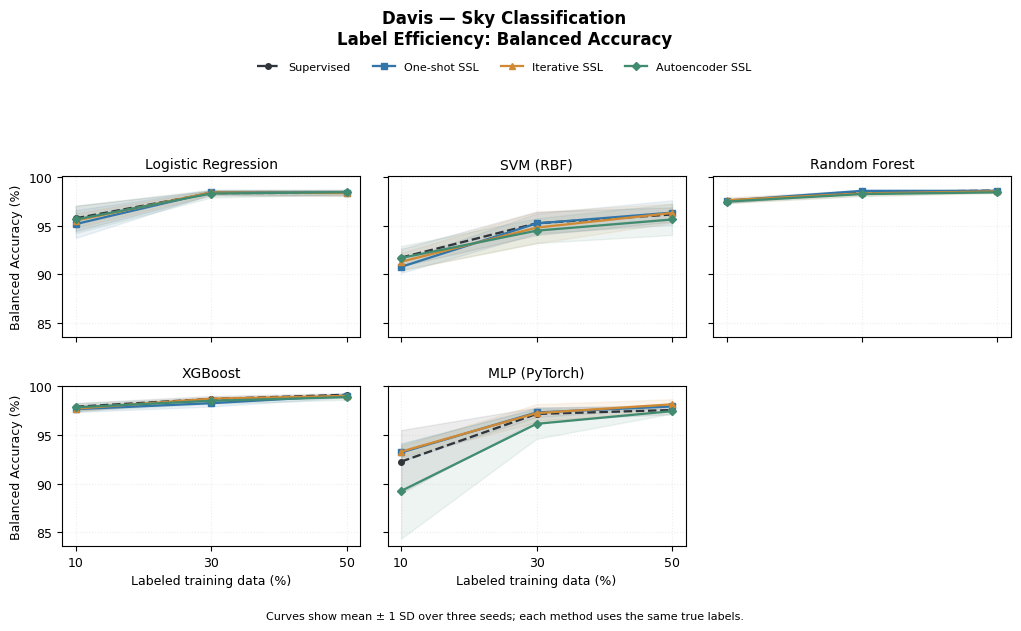

[SAVED] P4_Davis_Sky_Macro_F1_All_Models.pdf


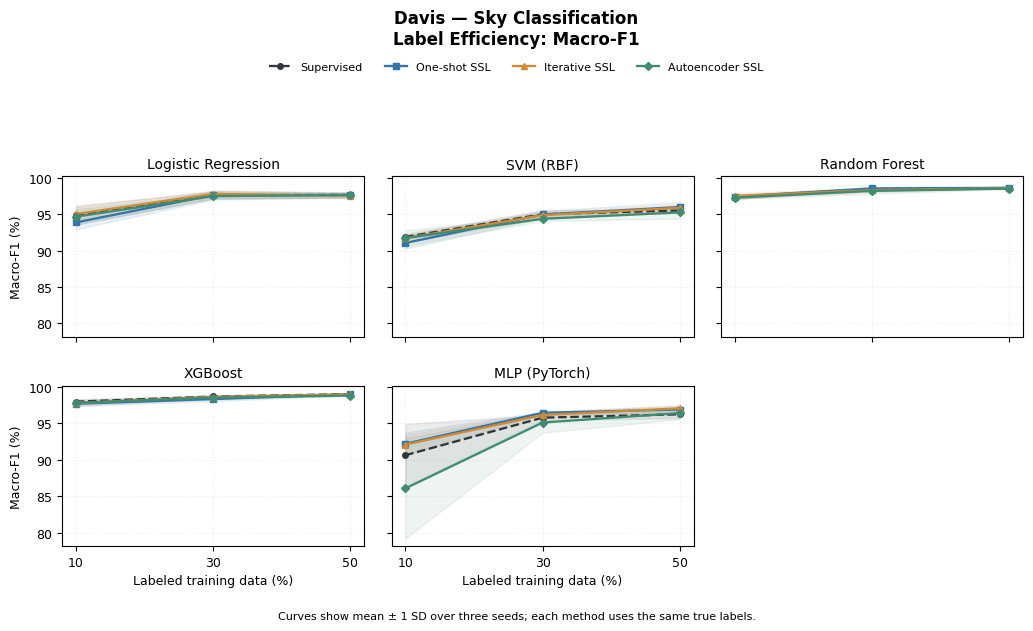

[SAVED] P4_Davis_Generation_Balanced_Accuracy_All_Models.pdf


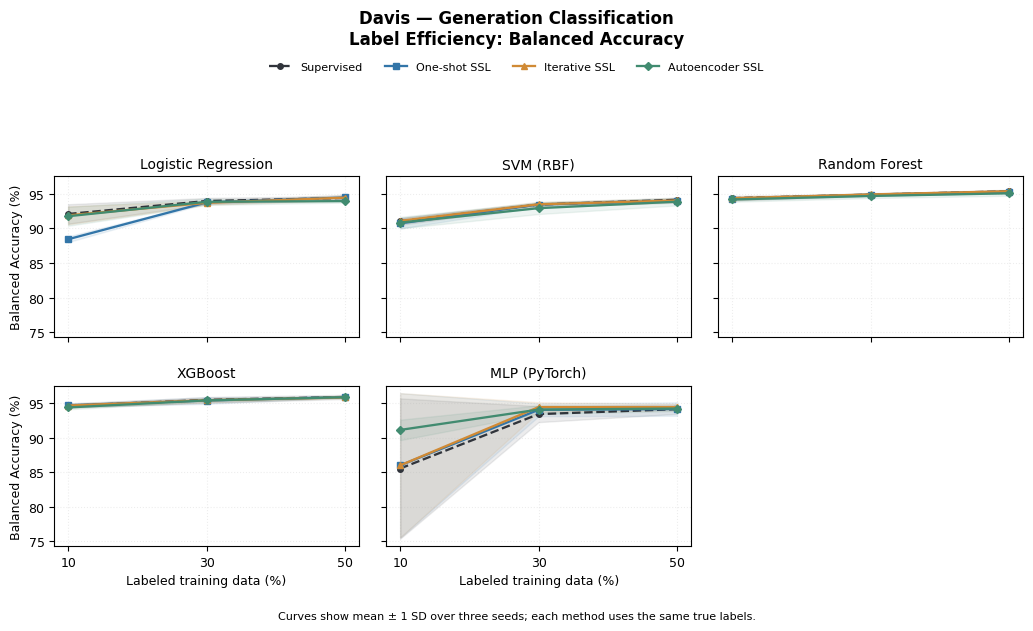

[SAVED] P4_Davis_Generation_Macro_F1_All_Models.pdf


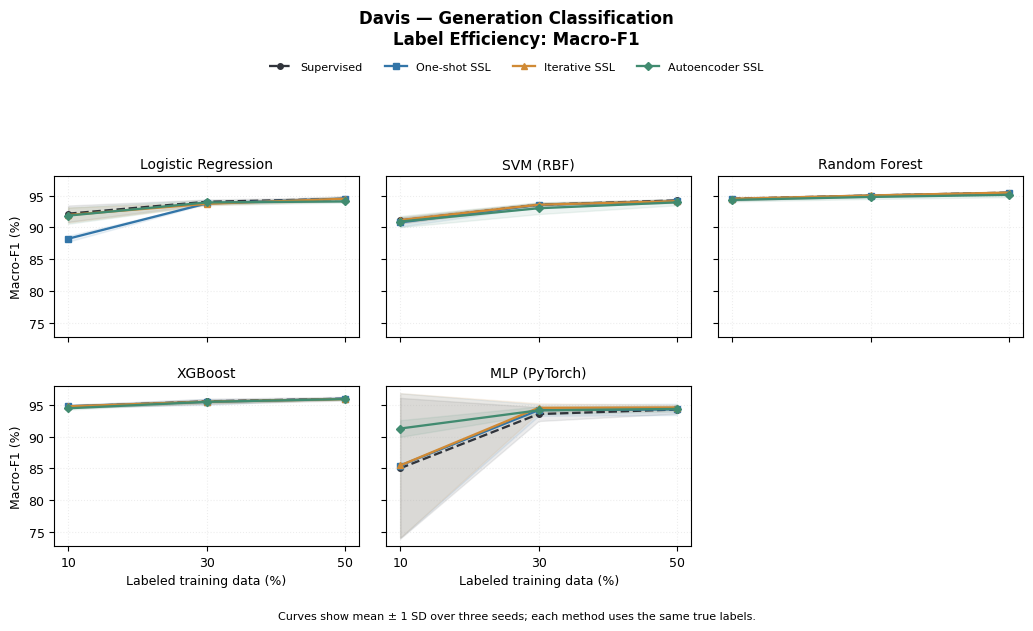

[SAVED] P4_Amherst_Sky_Balanced_Accuracy_All_Models.pdf


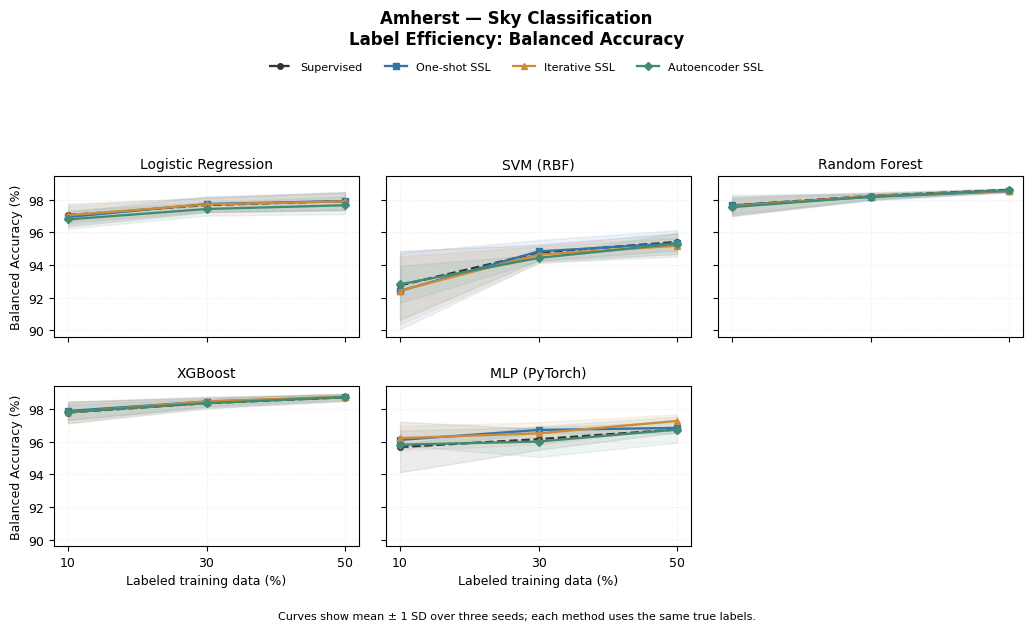

[SAVED] P4_Amherst_Sky_Macro_F1_All_Models.pdf


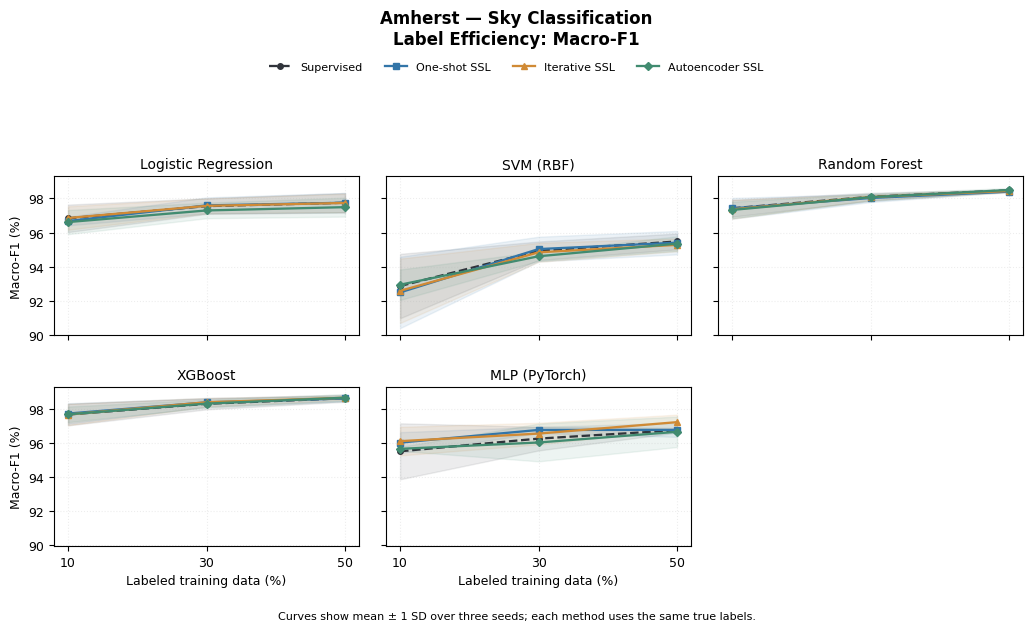

[SAVED] P4_Amherst_Generation_Balanced_Accuracy_All_Models.pdf


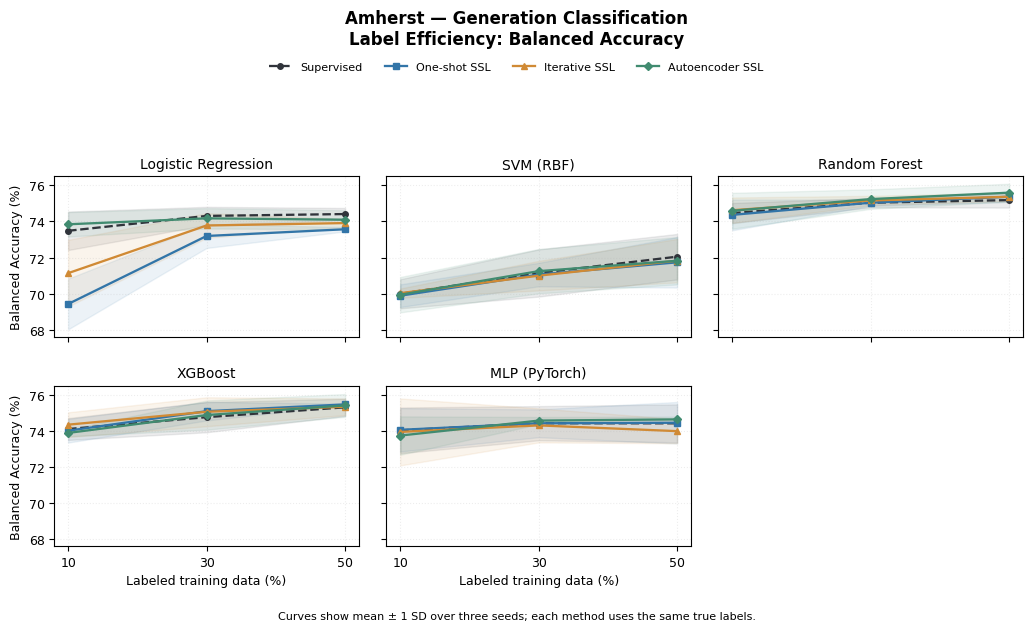

[SAVED] P4_Amherst_Generation_Macro_F1_All_Models.pdf


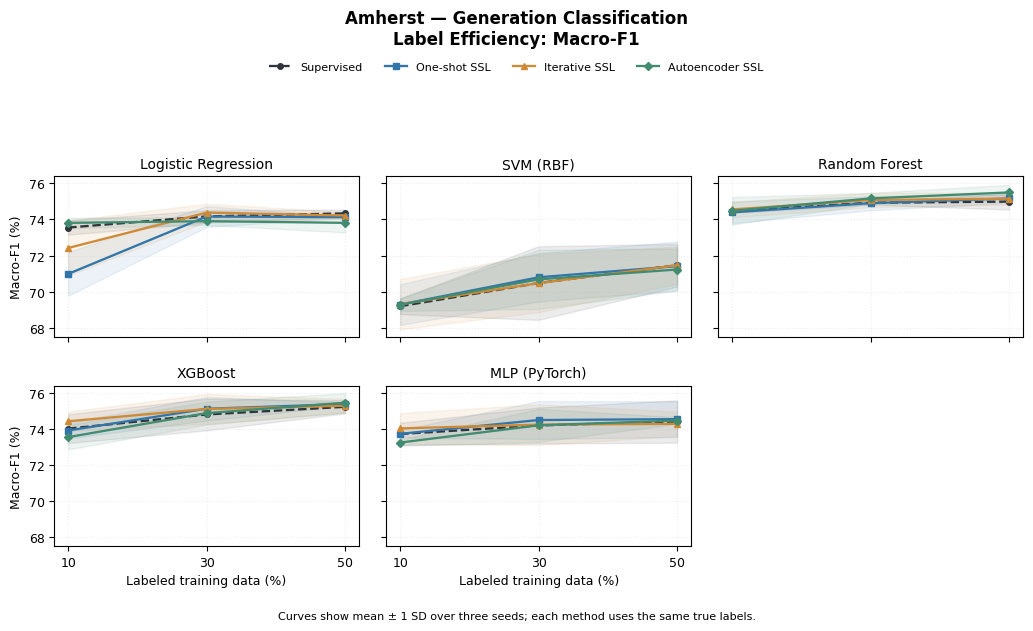

[SAVED] P4_Best_Observed_Label_Efficiency_Overview.pdf


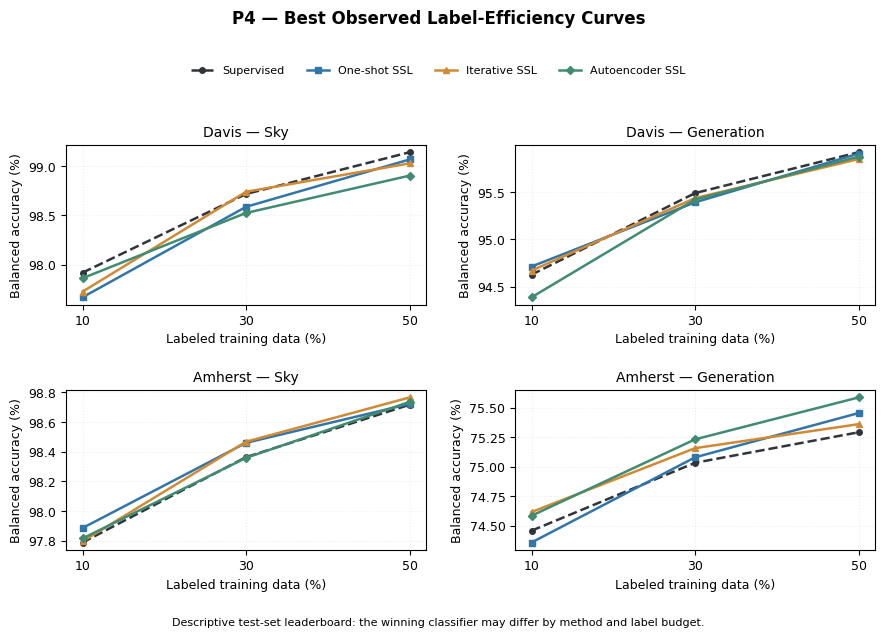


P4 — CONSOLIDATED EVALUATION

EXPERIMENT COUNTS
Total evaluations       : 720
Three-seed summary rows : 240
Matched SSL comparisons : 540
Figures prepared        : 9
Save vector PDFs        : True

OVERALL SSL COMPARISON


,Method,Evaluations,Improved,Mean_Gain_pp,Median_Gain_pp,Mean_MacroF1_Gain_pp
0,Iterative SSL,180,70,-0.0135,-0.0500,0.0832
1,Autoencoder SSL,180,66,-0.0626,-0.1082,-0.0852
2,One-shot SSL,180,73,-0.1489,-0.0156,-0.0626



BEST MATCHED-MODEL GAINS AT 10% LABELS


,City,Task,Method,Model,BalAcc_Gain_pp,BalAcc_Gain_SD,MacroF1_Gain_pp
0,Amherst,Generation,Autoencoder SSL,Logistic Regression,0.3599,0.3898,0.2588
1,Amherst,Sky,Iterative SSL,MLP (PyTorch),0.5450,0.8078,0.5937
2,Davis,Generation,Autoencoder SSL,MLP (PyTorch),5.5883,8.7962,6.2577
3,Davis,Sky,Iterative SSL,MLP (PyTorch),1.0285,2.6604,1.4605



SAVED SUMMARY FILES
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/P4_All_Experiment_Metrics.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/P4_All_Methods_Summary.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/P4_Matched_SSL_Gains.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/P4_Matched_SSL_Gains_Summary.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4/P4_Label_Efficiency_AUC.csv

No model training was performed in this cell.

All 9 vector PDFs were exported.


In [8]:

# ============================================================
# P4 — Cell 8: Consolidated Results and Label-Efficiency Plots
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SAVE_FINAL_FIGURES = True

P4_RESULT_SOURCES = {
    "Supervised": RESULTS_DIR / "supervised_baseline_metrics.csv",
    "One-shot SSL": RESULTS_DIR / "pseudo_label_metrics.csv",
    "Iterative SSL": RESULTS_DIR / "iterative_self_training_metrics.csv",
    "Autoencoder SSL": RESULTS_DIR / "autoencoder_ssl_metrics.csv"
}

P4_METHOD_STYLES = {
    "Supervised": {
        "color": "#30343b",
        "marker": "o",
        "linestyle": "--"
    },
    "One-shot SSL": {
        "color": "#3275a8",
        "marker": "s",
        "linestyle": "-"
    },
    "Iterative SSL": {
        "color": "#d08a35",
        "marker": "^",
        "linestyle": "-"
    },
    "Autoencoder SSL": {
        "color": "#418b70",
        "marker": "D",
        "linestyle": "-"
    }
}

P4_METRIC_COLUMNS = {
    "Balanced Accuracy": ("BalAcc_Mean", "BalAcc_SD"),
    "Macro-F1": ("MacroF1_Mean", "MacroF1_SD")
}

P4_KEYS = [
    "City", "Task",
    "Labeled Percentage", "Model", "Seed"
]


# ------------------------------------------------------------
# 1. Load and validate all four experimental approaches
# ------------------------------------------------------------

result_frames = []

for method, path in P4_RESULT_SOURCES.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    frame = pd.read_csv(path)

    required = P4_KEYS + [
        "Balanced Accuracy",
        "Macro-F1",
        "Accuracy"
    ]

    missing = [
        column for column in required
        if column not in frame.columns
    ]

    if missing:
        raise ValueError(
            f"{method}: Missing columns {missing}"
        )

    if len(frame) != 180:
        raise ValueError(
            f"{method}: Expected 180 records, "
            f"found {len(frame)}"
        )

    if frame.duplicated(P4_KEYS).any():
        raise ValueError(
            f"{method}: Duplicate experiment keys"
        )

    frame = frame[required].copy()
    frame["Method"] = method

    for metric in (
        "Balanced Accuracy",
        "Macro-F1",
        "Accuracy"
    ):
        assert frame[metric].between(0, 1).all()

    result_frames.append(frame)

P4_ALL_RESULTS = pd.concat(
    result_frames,
    ignore_index=True
)

assert len(P4_ALL_RESULTS) == 720

assert not P4_ALL_RESULTS.duplicated(
    P4_KEYS + ["Method"]
).any()

expected_fractions = {10, 30, 50}

for method, group in P4_ALL_RESULTS.groupby("Method"):
    assert set(group["Labeled Percentage"]) == (
        expected_fractions
    )
    assert set(group["Seed"]) == set(SEEDS)
    assert set(group["Model"]) == set(P4_MODELS)

P4_ALL_RESULTS.to_csv(
    RESULTS_DIR / "P4_All_Experiment_Metrics.csv",
    index=False
)


# ------------------------------------------------------------
# 2. Compute mean and standard deviation across seeds
# ------------------------------------------------------------

P4_SUMMARY = P4_ALL_RESULTS.groupby(
    [
        "City", "Task",
        "Labeled Percentage",
        "Model", "Method"
    ],
    as_index=False
).agg(
    BalAcc_Mean=("Balanced Accuracy", "mean"),
    BalAcc_SD=("Balanced Accuracy", "std"),
    MacroF1_Mean=("Macro-F1", "mean"),
    MacroF1_SD=("Macro-F1", "std"),
    Accuracy_Mean=("Accuracy", "mean"),
    Runs=("Seed", "count")
)

assert len(P4_SUMMARY) == 240
assert (P4_SUMMARY["Runs"] == 3).all()

P4_SUMMARY.to_csv(
    RESULTS_DIR / "P4_All_Methods_Summary.csv",
    index=False
)


# ------------------------------------------------------------
# 3. Compute paired SSL gains over supervised-only learning
# ------------------------------------------------------------

supervised = (
    P4_ALL_RESULTS[
        P4_ALL_RESULTS["Method"] == "Supervised"
    ][
        P4_KEYS + [
            "Balanced Accuracy", "Macro-F1"
        ]
    ]
    .rename(columns={
        "Balanced Accuracy": "Supervised_BalAcc",
        "Macro-F1": "Supervised_MacroF1"
    })
)

ssl = P4_ALL_RESULTS[
    P4_ALL_RESULTS["Method"] != "Supervised"
].copy()

P4_MATCHED_GAINS = ssl.merge(
    supervised,
    on=P4_KEYS,
    how="inner",
    validate="many_to_one"
)

assert len(P4_MATCHED_GAINS) == 540

P4_MATCHED_GAINS["BalAcc_Gain_pp"] = 100 * (
    P4_MATCHED_GAINS["Balanced Accuracy"]
    - P4_MATCHED_GAINS["Supervised_BalAcc"]
)

P4_MATCHED_GAINS["MacroF1_Gain_pp"] = 100 * (
    P4_MATCHED_GAINS["Macro-F1"]
    - P4_MATCHED_GAINS["Supervised_MacroF1"]
)

P4_MATCHED_GAINS.to_csv(
    RESULTS_DIR / "P4_Matched_SSL_Gains.csv",
    index=False
)

P4_GAIN_SUMMARY = P4_MATCHED_GAINS.groupby(
    [
        "City", "Task",
        "Labeled Percentage",
        "Model", "Method"
    ],
    as_index=False
).agg(
    BalAcc_Gain_pp=("BalAcc_Gain_pp", "mean"),
    BalAcc_Gain_SD=("BalAcc_Gain_pp", "std"),
    MacroF1_Gain_pp=("MacroF1_Gain_pp", "mean"),
    Improved_Seeds=(
        "BalAcc_Gain_pp",
        lambda values: int((values > 0).sum())
    )
)

P4_GAIN_SUMMARY.to_csv(
    RESULTS_DIR / "P4_Matched_SSL_Gains_Summary.csv",
    index=False
)


# ------------------------------------------------------------
# 4. Label-efficiency AUC over 10%, 30%, and 50% labels
# ------------------------------------------------------------

auc_records = []

for keys, group in P4_ALL_RESULTS.groupby(
    ["City", "Task", "Model", "Method", "Seed"]
):

    city, task, model, method, seed = keys

    ordered = group.sort_values(
        "Labeled Percentage"
    )

    x = (
        ordered["Labeled Percentage"].to_numpy(
            dtype=float
        ) / 100
    )

    assert np.allclose(x, [0.10, 0.30, 0.50])

    for metric in ("Balanced Accuracy", "Macro-F1"):

        values = ordered[metric].to_numpy(
            dtype=float
        )

        # Integrate only over the evaluated label budget.
        area = np.trapezoid(values, x)

        auc_records.append({
            "City": city,
            "Task": task,
            "Model": model,
            "Method": method,
            "Seed": seed,
            "Metric": metric,
            "AUC_10_to_50": area,
            "Normalized_AUC": area / (0.50 - 0.10)
        })

P4_AUC = pd.DataFrame(auc_records)

assert len(P4_AUC) == 480

P4_AUC.to_csv(
    RESULTS_DIR / "P4_Label_Efficiency_AUC.csv",
    index=False
)


# ------------------------------------------------------------
# 5. Figure creation helper
# ------------------------------------------------------------

def finalize_p4_figure(fig, filename):

    if SAVE_FINAL_FIGURES:

        path = FIGURES_DIR / filename

        fig.savefig(
            path,
            format="pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"[SAVED] {path.name}")

    else:
        print(f"[PREVIEW] {filename}")

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 6. Label-efficiency curves for every classifier
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

figure_count = 0

for city in DATASET_FILES:

    for task in CLASSIFICATION_TASKS:

        for metric, (mean_col, sd_col) in (
            P4_METRIC_COLUMNS.items()
        ):

            fig, axes = plt.subplots(
                2, 3,
                figsize=(10.4, 6.1),
                sharex=True,
                sharey=True
            )

            flat_axes = axes.ravel()

            for index, model in enumerate(P4_MODELS):

                ax = flat_axes[index]

                for method, style in (
                    P4_METHOD_STYLES.items()
                ):

                    subset = P4_SUMMARY[
                        (P4_SUMMARY["City"] == city)
                        & (P4_SUMMARY["Task"] == task)
                        & (P4_SUMMARY["Model"] == model)
                        & (P4_SUMMARY["Method"] == method)
                    ].sort_values(
                        "Labeled Percentage"
                    )

                    assert len(subset) == 3

                    x = subset[
                        "Labeled Percentage"
                    ].to_numpy(dtype=float)

                    mean = subset[
                        mean_col
                    ].to_numpy(dtype=float)

                    sd = subset[
                        sd_col
                    ].to_numpy(dtype=float)

                    ax.plot(
                        x, 100 * mean,
                        color=style["color"],
                        marker=style["marker"],
                        linestyle=style["linestyle"],
                        linewidth=1.65,
                        markersize=4,
                        label=method
                    )

                    ax.fill_between(
                        x,
                        100 * (mean - sd),
                        100 * (mean + sd),
                        color=style["color"],
                        alpha=0.09
                    )

                ax.set_title(model)
                ax.set_xticks([10, 30, 50])
                ax.grid(
                    alpha=0.22,
                    linestyle=":"
                )

                if index >= 3:
                    ax.set_xlabel("Labeled training data (%)")

                if index in (0, 3):
                    ax.set_ylabel(f"{metric} (%)")

            flat_axes[5].axis("off")

            handles, labels = (
                flat_axes[0].get_legend_handles_labels()
            )

            fig.legend(
                handles, labels,
                loc="upper center",
                bbox_to_anchor=(0.5, 0.945),
                ncol=4,
                frameon=False
            )

            fig.suptitle(
                f"{city} — {task} Classification\n"
                f"Label Efficiency: {metric}",
                fontsize=12,
                fontweight="semibold",
                y=1.015
            )

            fig.text(
                0.5, 0.015,
                "Curves show mean ± 1 SD over three "
                "seeds; each method uses the same true labels.",
                ha="center",
                fontsize=8
            )

            fig.tight_layout(
                rect=(0, 0.045, 1, 0.88),
                w_pad=1.8,
                h_pad=2.0
            )

            metric_slug = (
                "Balanced_Accuracy"
                if metric == "Balanced Accuracy"
                else "Macro_F1"
            )

            finalize_p4_figure(
                fig,
                f"P4_{city}_{task}_"
                f"{metric_slug}_All_Models.pdf"
            )

            figure_count += 1


# ------------------------------------------------------------
# 7. Descriptive overview: best observed model per method
# ------------------------------------------------------------

# This overview is descriptive, not a validation-based
# model-selection procedure. The all-model curves above
# are the primary comparison.

best_observed = (
    P4_SUMMARY
    .sort_values(
        "BalAcc_Mean",
        ascending=False
    )
    .drop_duplicates(
        [
            "City", "Task",
            "Labeled Percentage", "Method"
        ]
    )
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(9.0, 6.2)
)

for ax, (city, task) in zip(
    axes.ravel(),
    [
        ("Davis", "Sky"),
        ("Davis", "Generation"),
        ("Amherst", "Sky"),
        ("Amherst", "Generation")
    ]
):

    for method, style in P4_METHOD_STYLES.items():

        subset = best_observed[
            (best_observed["City"] == city)
            & (best_observed["Task"] == task)
            & (best_observed["Method"] == method)
        ].sort_values(
            "Labeled Percentage"
        )

        assert len(subset) == 3

        ax.plot(
            subset["Labeled Percentage"],
            100 * subset["BalAcc_Mean"],
            color=style["color"],
            marker=style["marker"],
            linestyle=style["linestyle"],
            linewidth=1.8,
            markersize=4,
            label=method
        )

    ax.set_title(f"{city} — {task}")
    ax.set_xlabel("Labeled training data (%)")
    ax.set_ylabel("Balanced accuracy (%)")
    ax.set_xticks([10, 30, 50])
    ax.grid(alpha=0.22, linestyle=":")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=4,
    frameon=False
)

fig.suptitle(
    "P4 — Best Observed Label-Efficiency Curves",
    fontsize=12,
    fontweight="semibold",
    y=1.005
)

fig.text(
    0.5, 0.012,
    "Descriptive test-set leaderboard: the winning "
    "classifier may differ by method and label budget.",
    ha="center",
    fontsize=8
)

fig.tight_layout(
    rect=(0, 0.045, 1, 0.89),
    w_pad=2.0,
    h_pad=2.0
)

finalize_p4_figure(
    fig,
    "P4_Best_Observed_Label_Efficiency_Overview.pdf"
)

figure_count += 1


# ------------------------------------------------------------
# 8. Print consolidated results
# ------------------------------------------------------------

method_comparison = (
    P4_MATCHED_GAINS.groupby(
        "Method",
        as_index=False
    )
    .agg(
        Evaluations=("BalAcc_Gain_pp", "size"),
        Improved=("BalAcc_Gain_pp", lambda x: int((x > 0).sum())),
        Mean_Gain_pp=("BalAcc_Gain_pp", "mean"),
        Median_Gain_pp=("BalAcc_Gain_pp", "median"),
        Mean_MacroF1_Gain_pp=("MacroF1_Gain_pp", "mean")
    )
    .sort_values("Mean_Gain_pp", ascending=False)
)

ten_percent_gain = (
    P4_GAIN_SUMMARY[
        P4_GAIN_SUMMARY["Labeled Percentage"] == 10
    ]
    .sort_values(
        "BalAcc_Gain_pp",
        ascending=False
    )
    .drop_duplicates(["City", "Task"])
    .sort_values(["City", "Task"])
)

print("\n" + "=" * 75)
print("P4 — CONSOLIDATED EVALUATION")
print("=" * 75)

print("\nEXPERIMENT COUNTS")
print(f"Total evaluations       : {len(P4_ALL_RESULTS)}")
print(f"Three-seed summary rows : {len(P4_SUMMARY)}")
print(f"Matched SSL comparisons : {len(P4_MATCHED_GAINS)}")
print(f"Figures prepared        : {figure_count}")
print(f"Save vector PDFs        : {SAVE_FINAL_FIGURES}")

print("\nOVERALL SSL COMPARISON")
display(
    method_comparison.round(4).reset_index(drop=True)
)

print("\nBEST MATCHED-MODEL GAINS AT 10% LABELS")
display(
    ten_percent_gain[
        [
            "City",
            "Task",
            "Method",
            "Model",
            "BalAcc_Gain_pp",
            "BalAcc_Gain_SD",
            "MacroF1_Gain_pp"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nSAVED SUMMARY FILES")
for filename in (
    "P4_All_Experiment_Metrics.csv",
    "P4_All_Methods_Summary.csv",
    "P4_Matched_SSL_Gains.csv",
    "P4_Matched_SSL_Gains_Summary.csv",
    "P4_Label_Efficiency_AUC.csv"
):
    print(f"  {RESULTS_DIR / filename}")

print("\nNo model training was performed in this cell.")

if not SAVE_FINAL_FIGURES:
    print(
        "\nFigures are in preview mode. "
        "Set SAVE_FINAL_FIGURES=True and rerun this "
        "cell to export the PDF figures."
    )
else:
    print(f"\nAll {figure_count} vector PDFs were exported.")


[SAVED] P4_Davis_Sky_Confusion_Matrices_10pct.pdf


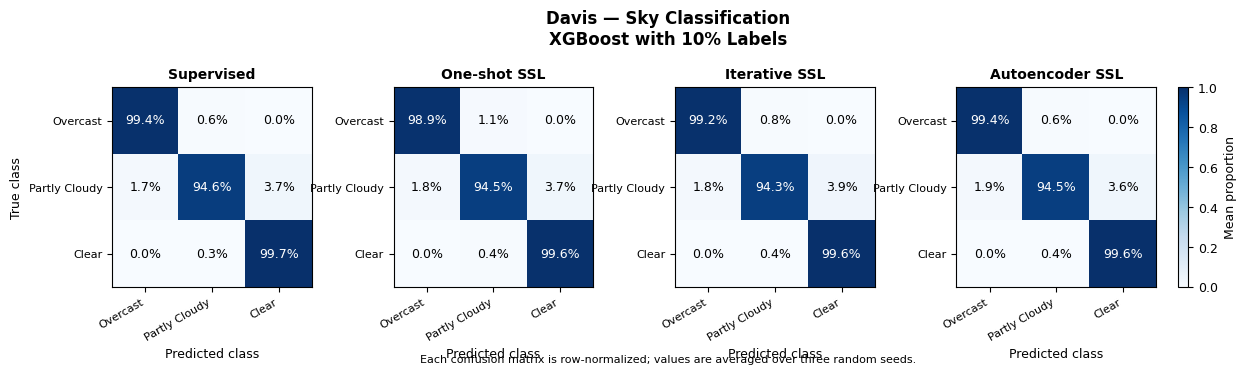

[SAVED] P4_Davis_Generation_Confusion_Matrices_10pct.pdf


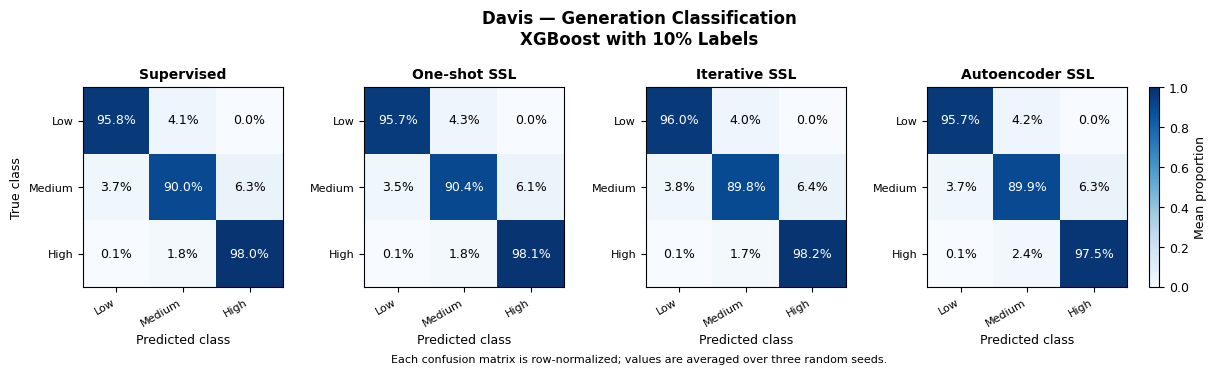

[SAVED] P4_Amherst_Sky_Confusion_Matrices_10pct.pdf


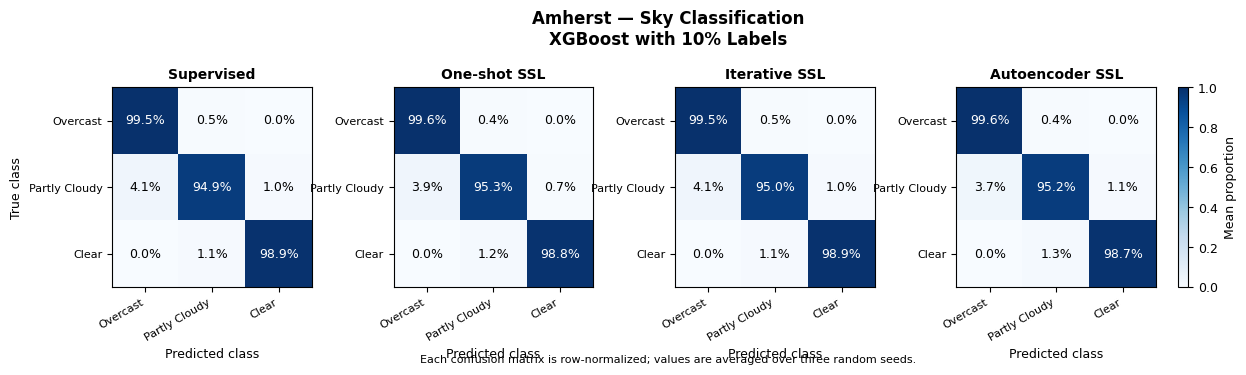

[SAVED] P4_Amherst_Generation_Confusion_Matrices_10pct.pdf


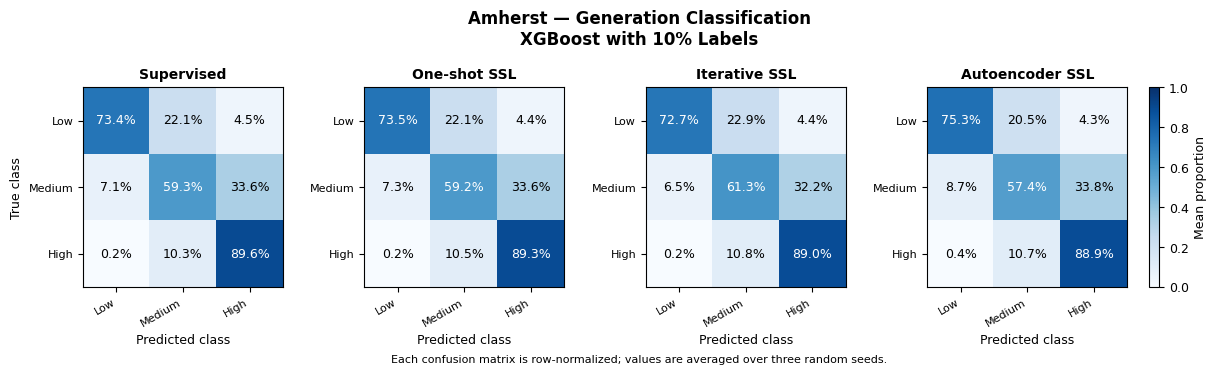


P4 — FINAL CLASSIFICATION ANALYSIS

LABEL-EFFICIENCY AUC — XGBOOST
Normalized AUC is measured over 10%–50% labels.


,City,Task,Method,AUC_Mean,AUC_SD
0,Amherst,Generation,Autoencoder SSL,0.7475,0.0057
1,Amherst,Generation,Iterative SSL,0.7494,0.0035
2,Amherst,Generation,One-shot SSL,0.7490,0.0010
3,Amherst,Generation,Supervised,0.7472,0.0037
4,Amherst,Sky,Autoencoder SSL,0.9832,0.0028
5,Amherst,Sky,Iterative SSL,0.9837,0.0033
6,Amherst,Sky,One-shot SSL,0.9838,0.0032
7,Amherst,Sky,Supervised,0.9831,0.0035
8,Davis,Generation,Autoencoder SSL,0.9527,0.0011
9,Davis,Generation,Iterative SSL,0.9535,0.0019



AUC GAIN OVER MATCHED SUPERVISED BASELINE
Positive values indicate higher label efficiency.


,City,Task,Method,AUC_Gain_pp,AUC_Gain_SD
0,Amherst,Generation,Autoencoder SSL,0.0303,0.2048
1,Amherst,Generation,Iterative SSL,0.2174,0.1089
2,Amherst,Generation,One-shot SSL,0.1828,0.2794
3,Amherst,Sky,Autoencoder SSL,0.0091,0.0710
4,Amherst,Sky,Iterative SSL,0.0661,0.0219
5,Amherst,Sky,One-shot SSL,0.0739,0.0226
6,Davis,Generation,Autoencoder SSL,-0.1056,0.2086
7,Davis,Generation,Iterative SSL,-0.0340,0.1228
8,Davis,Generation,One-shot SSL,-0.0311,0.0241
9,Davis,Sky,Autoencoder SSL,-0.1701,0.1715



PER-CLASS RECALL — XGBOOST AT 10% LABELS


,City,Task,Method,Class,Recall_Mean,Recall_SD
0,Amherst,Generation,Autoencoder SSL,High,0.8893,0.0163
1,Amherst,Generation,Autoencoder SSL,Low,0.7528,0.0367
2,Amherst,Generation,Autoencoder SSL,Medium,0.5742,0.0487
3,Amherst,Generation,Iterative SSL,High,0.8897,0.0066
4,Amherst,Generation,Iterative SSL,Low,0.7270,0.0466
5,Amherst,Generation,Iterative SSL,Medium,0.6133,0.0420
6,Amherst,Generation,One-shot SSL,High,0.8933,0.0073
7,Amherst,Generation,One-shot SSL,Low,0.7351,0.0428
8,Amherst,Generation,One-shot SSL,Medium,0.5916,0.0371
9,Amherst,Generation,Supervised,High,0.8957,0.0097



FINAL OUTPUTS
Confusion matrix figures : 4
Figures directory        : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P4
Results directory        : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P4
Export PDFs              : True

No models were trained or refitted.
All four confusion matrix PDFs exported.


In [10]:

# ============================================================
# P4 — Cell 9: Confusion Matrices and Final AUC Analysis
# ============================================================

from sklearn.metrics import confusion_matrix

SAVE_P4_CONFUSION_FIGURES = True

P4_CM_MODEL = "XGBoost"
P4_CM_FRACTION = 0.10

P4_CM_METHOD_DIRS = {
    "Supervised": P4_BASELINE_PREDICTIONS,
    "One-shot SSL": P4_PSEUDO_PREDICTIONS_DIR,
    "Iterative SSL": P4_ST_PREDICTIONS_DIR,
    "Autoencoder SSL": P4_AE_PRED_DIR
}

P4_CM_METHODS = tuple(P4_CM_METHOD_DIRS)

recall_records = []
figure_count = 0


# ------------------------------------------------------------
# 1. Verify and load saved predictions
# ------------------------------------------------------------

def load_p4_cm_predictions(
    city, task, method, seed
):
    """
    Load previously saved test predictions.

    Predictions are verified against the original
    held-out test observations and their row IDs.
    """

    experiment = get_p4_experiment(
        city,
        task,
        P4_CM_FRACTION,
        seed
    )

    filename = p4_baseline_prediction_path(
        city,
        task,
        P4_CM_FRACTION,
        P4_CM_MODEL,
        seed
    ).name

    path = P4_CM_METHOD_DIRS[method] / filename

    if not path.is_file():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as saved:
        row_index = saved["row_index"].copy()
        y_true = saved["y_true"].copy()
        y_pred = saved["y_pred"].copy()

    np.testing.assert_array_equal(
        row_index,
        experiment["test_row_index"]
    )

    np.testing.assert_array_equal(
        y_true,
        experiment["y_test"]
    )

    assert y_pred.shape == y_true.shape
    assert np.isin(y_pred, [0, 1, 2]).all()

    return y_true, y_pred


# ------------------------------------------------------------
# 2. Generate confusion matrices for both cities and tasks
# ------------------------------------------------------------

for city in DATASET_FILES:

    for task in CLASSIFICATION_TASKS:

        class_names = CLASS_NAMES[task]

        fig, axes = plt.subplots(
            1, 4,
            figsize=(12.8, 3.7)
        )

        for ax, method in zip(
            axes,
            P4_CM_METHODS
        ):

            seed_matrices = []

            for seed in SEEDS:

                y_true, y_pred = load_p4_cm_predictions(
                    city,
                    task,
                    method,
                    seed
                )

                matrix = confusion_matrix(
                    y_true,
                    y_pred,
                    labels=[0, 1, 2]
                )

                class_support = matrix.sum(axis=1)

                assert (class_support > 0).all()

                normalized = (
                    matrix
                    / class_support[:, None]
                )

                seed_matrices.append(normalized)

                for class_id, class_name in enumerate(
                    class_names
                ):

                    recall_records.append({
                        "City": city,
                        "Task": task,
                        "Method": method,
                        "Model": P4_CM_MODEL,
                        "Labeled Percentage": 10,
                        "Seed": seed,
                        "Class": class_name,
                        "Support": int(
                            class_support[class_id]
                        ),
                        "Recall": normalized[
                            class_id, class_id
                        ]
                    })

            # Mean normalized confusion matrix
            # across the three independent seeds.
            mean_matrix = np.mean(
                seed_matrices,
                axis=0
            )

            image = ax.imshow(
                mean_matrix,
                cmap="Blues",
                vmin=0,
                vmax=1
            )

            for row in range(3):
                for column in range(3):

                    value = mean_matrix[row, column]

                    ax.text(
                        column,
                        row,
                        f"{100 * value:.1f}%",
                        ha="center",
                        va="center",
                        fontsize=9,
                        color=(
                            "white"
                            if value >= 0.55
                            else "black"
                        )
                    )

            ax.set_title(
                method,
                fontweight="semibold",
                fontsize=10
            )

            ax.set_xticks(range(3))
            ax.set_yticks(range(3))

            ax.set_xticklabels(
                class_names,
                rotation=30,
                ha="right",
                fontsize=8
            )

            ax.set_yticklabels(
                class_names,
                fontsize=8
            )

            ax.set_xlabel("Predicted class")

            if method == "Supervised":
                ax.set_ylabel("True class")

        fig.suptitle(
            f"{city} — {task} Classification\n"
            f"XGBoost with 10% Labels",
            fontsize=12,
            fontweight="semibold",
            y=0.99
        )

        fig.subplots_adjust(
            left=0.06,
            right=0.92,
            bottom=0.24,
            top=0.78,
            wspace=0.36
        )

        fig.colorbar(
            image,
            ax=axes.ravel().tolist(),
            fraction=0.025,
            pad=0.02,
            label="Mean proportion"
        )

        fig.text(
            0.5,
            0.035,
            "Each confusion matrix is row-normalized; "
            "values are averaged over three random seeds.",
            ha="center",
            fontsize=8
        )

        filename = (
            f"P4_{city}_{task}_"
            "Confusion_Matrices_10pct.pdf"
        )

        if SAVE_P4_CONFUSION_FIGURES:

            output_path = FIGURES_DIR / filename

            fig.savefig(
                output_path,
                format="pdf",
                bbox_inches="tight",
                facecolor="white"
            )

            print(f"[SAVED] {filename}")

        else:
            print(f"[PREVIEW] {filename}")

        plt.show()
        plt.close(fig)

        figure_count += 1


# ------------------------------------------------------------
# 3. Save per-class recall statistics
# ------------------------------------------------------------

P4_CLASS_RECALL = pd.DataFrame(
    recall_records
)

assert len(P4_CLASS_RECALL) == (
    2 * 2 * 4 * 3 * 3
)

P4_CLASS_RECALL.to_csv(
    RESULTS_DIR / "P4_Class_Recall_10pct.csv",
    index=False
)

P4_CLASS_RECALL_SUMMARY = (
    P4_CLASS_RECALL.groupby(
        ["City", "Task", "Method", "Class"],
        as_index=False
    )
    .agg(
        Recall_Mean=("Recall", "mean"),
        Recall_SD=("Recall", "std"),
        Support=("Support", "first"),
        Runs=("Seed", "count")
    )
)

assert (
    P4_CLASS_RECALL_SUMMARY["Runs"] == 3
).all()

P4_CLASS_RECALL_SUMMARY.to_csv(
    RESULTS_DIR / "P4_Class_Recall_10pct_Summary.csv",
    index=False
)


# ------------------------------------------------------------
# 4. Summarize label-efficiency AUC
# ------------------------------------------------------------

auc_data = pd.read_csv(
    RESULTS_DIR / "P4_Label_Efficiency_AUC.csv"
)

auc_data = auc_data[
    (auc_data["Metric"] == "Balanced Accuracy")
    & (auc_data["Model"] == P4_CM_MODEL)
].copy()

auc_summary = (
    auc_data.groupby(
        ["City", "Task", "Method"],
        as_index=False
    )
    .agg(
        AUC_Mean=("Normalized_AUC", "mean"),
        AUC_SD=("Normalized_AUC", "std"),
        Runs=("Seed", "count")
    )
)

assert len(auc_summary) == 16
assert (auc_summary["Runs"] == 3).all()

auc_summary.to_csv(
    RESULTS_DIR / "P4_XGBoost_Label_Efficiency_AUC_Summary.csv",
    index=False
)


# ------------------------------------------------------------
# 5. Compare normalized AUC with supervised-only learning
# ------------------------------------------------------------

supervised_auc = (
    auc_data[
        auc_data["Method"] == "Supervised"
    ][
        ["City", "Task", "Seed", "Normalized_AUC"]
    ]
    .rename(columns={
        "Normalized_AUC": "Supervised_AUC"
    })
)

ssl_auc = auc_data[
    auc_data["Method"] != "Supervised"
].merge(
    supervised_auc,
    on=["City", "Task", "Seed"],
    validate="many_to_one"
)

ssl_auc["AUC_Gain_pp"] = 100 * (
    ssl_auc["Normalized_AUC"]
    - ssl_auc["Supervised_AUC"]
)

auc_gain_summary = (
    ssl_auc.groupby(
        ["City", "Task", "Method"],
        as_index=False
    )
    .agg(
        AUC_Gain_pp=("AUC_Gain_pp", "mean"),
        AUC_Gain_SD=("AUC_Gain_pp", "std")
    )
)

auc_gain_summary.to_csv(
    RESULTS_DIR / "P4_XGBoost_AUC_Gains.csv",
    index=False
)


# ------------------------------------------------------------
# 6. Display final summaries
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P4 — FINAL CLASSIFICATION ANALYSIS")
print("=" * 75)

print("\nLABEL-EFFICIENCY AUC — XGBOOST")
print("Normalized AUC is measured over 10%–50% labels.")

display(
    auc_summary[
        [
            "City",
            "Task",
            "Method",
            "AUC_Mean",
            "AUC_SD"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nAUC GAIN OVER MATCHED SUPERVISED BASELINE")
print("Positive values indicate higher label efficiency.")

display(
    auc_gain_summary.round(4).reset_index(drop=True)
)

print("\nPER-CLASS RECALL — XGBOOST AT 10% LABELS")

display(
    P4_CLASS_RECALL_SUMMARY[
        [
            "City",
            "Task",
            "Method",
            "Class",
            "Recall_Mean",
            "Recall_SD"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nFINAL OUTPUTS")
print(f"Confusion matrix figures : {figure_count}")
print(f"Figures directory        : {FIGURES_DIR}")
print(f"Results directory        : {RESULTS_DIR}")
print(f"Export PDFs              : {SAVE_P4_CONFUSION_FIGURES}")

print("\nNo models were trained or refitted.")

if not SAVE_P4_CONFUSION_FIGURES:
    print(
        "Inspect the four figures, then set "
        "SAVE_P4_CONFUSION_FIGURES=True and "
        "rerun this cell to export them."
    )
else:
    print("All four confusion matrix PDFs exported.")
